# 1. Basic Quantization Answer

## Goals

본 실습에서는 CNN(Convolutional Neural Network)을 **양자화(Quantization)**하여 모델의 크기와 실행 시간을 줄이는 방법을 실습합니다.

## Contents
1. **Uniform Quantization**
  - **Linear quantization**을 구현하고 적용합니다.
  - **Linear quantization**을 위한 **Integer-only inference**를 구현하고 적용합니다.
2. **Non-uniform Quantization**
  - **K-means quantization**을 구현하고 적용합니다.
3. **Quantization with PyTorch API**
  - **Post-Training Quantization** (PTQ)
  - **Quantization-Aware Training** (QAT)

## Setup

먼저 노트북 안에서 필요한 패키지를 설치한 뒤, CIFAR10 데이터셋과 사전 학습된 VGG 모델을 준비합니다. 파일은 노트북을 실행한 작업 디렉터리 기준으로 저장됩니다.


### 패키지 설치 (노트북에서 바로 실행)

아래 **① PyTorch 설치 확인 → ② `%pip install`** 셀을 순서대로 실행하면 됩니다. 별도 `README`나 `requirements` 파일을 참조할 필요는 없습니다. `%pip`는 `!pip`와 달리 **현재 Jupyter 커널의 Python 환경**에 패키지를 설치합니다.

- **Windows 10/11 x64 / Python 3.11 권장.** Linux에서도 동일한 노트북을 사용할 수 있습니다.
- PyTorch가 설치되어 있지 않으면 NVIDIA GPU 탐지 결과에 따라 CUDA 또는 CPU 버전을 설치합니다. 이미 설치되어 있다면 기존 환경을 유지합니다. 설치된 PyTorch가 CPU 빌드라면 위 셀의 `FORCE_REINSTALL_TORCH`를 설정할 수 있습니다.
- RTX 50 / Blackwell GPU는 CUDA 12.8용 PyTorch를 선택합니다. GPU 드라이버가 해당 CUDA 런타임을 지원해야 합니다.
- 설치 직후 이전에 다른 셀에서 PyTorch / Transformers를 import했다면 **커널을 재시작한 후 처음부터 다시 실행**하세요.
- `fast-pytorch-kmeans`는 선택 패키지로, Basic 실습에서 설치를 시도하며 불가한 환경에서는 `scikit-learn`의 대체 구현을 사용합니다.
- **`llama.cpp` 실행 바이너리는 pip 패키지가 아닙니다.** Basic 실습의 별도 다운로드 셀에서 공식 b10711 Windows 실행 파일 및 필요한 CUDA DLL을 설치합니다.


In [1]:
# ① PyTorch 설치 (Windows / Linux, 현재 Jupyter 커널에 설치)
# 이미 torch와 torchvision이 모두 설치되어 있으면 유지합니다.
# GPU 빌드를 강제로 지정해야 하는 경우 아래 값을 'cpu', 'cu121', 'cu128' 중 하나로 변경하세요.
TORCH_BACKEND = 'auto'  # 'auto' | 'cpu' | 'cu121' | 'cu128'
FORCE_REINSTALL_TORCH = False

import sys
import shutil
import subprocess
from importlib import metadata as _pkg_metadata

if not (3, 10) <= sys.version_info[:2] <= (3, 12):
    print('주의: Python 3.11 권장 (현재:', sys.version.split()[0], ')')


def _installed_version(name):
    try:
        return _pkg_metadata.version(name)
    except _pkg_metadata.PackageNotFoundError:
        return None


def _nvidia_gpu_info():
    """Windows/Linux에서 CUDA 실행 가능 GPU 탐지 (PyTorch import 전에 확인)."""
    if shutil.which('nvidia-smi') is None:
        return ''
    try:
        result = subprocess.run(
            ['nvidia-smi', '--query-gpu=name,compute_cap', '--format=csv,noheader'],
            capture_output=True, text=True, timeout=15, check=False,
        )
        if result.returncode == 0 and result.stdout.strip():
            return result.stdout.strip()
        fallback = subprocess.run(
            ['nvidia-smi', '-L'], capture_output=True, text=True, timeout=15, check=False,
        )
        return fallback.stdout.strip() if fallback.returncode == 0 else ''
    except (OSError, subprocess.TimeoutExpired):
        return ''


_gpu_info = _nvidia_gpu_info()
_backend = TORCH_BACKEND
if _backend == 'auto':
    if not _gpu_info:
        _backend = 'cpu'
    else:
        # Blackwell GPU (compute capability >= 10)는 2.5.1의 CUDA 12.1 빌드 대신 cu128 사용
        import re
        cc_values = [float(x) for x in re.findall(r'(?<!\d)(\d+\.\d+)(?!\d)', _gpu_info)]
        blackwell = any(v >= 10 for v in cc_values) or bool(
            re.search(r'RTX\s*(?:PRO\s*)?50\d{2}|Blackwell', _gpu_info, re.I)
        )
        _backend = 'cu128' if blackwell else 'cu121'

if _backend not in {'cpu', 'cu121', 'cu128'}:
    raise ValueError("TORCH_BACKEND는 'auto', 'cpu', 'cu121', 'cu128' 중 하나여야 합니다.")

_have_torch = _installed_version('torch')
_have_vision = _installed_version('torchvision')
print('Detected GPU:', _gpu_info if _gpu_info else '없음 (CPU)')
print('PyTorch wheel 선택:', _backend)

if FORCE_REINSTALL_TORCH or not (_have_torch and _have_vision):
    _torch_pin, _vision_pin = (
        ('2.7.0', '0.22.0') if _backend == 'cu128' else ('2.5.1', '0.20.1')
    )
    _torch_pip_args = [
        sys.executable, '-m', 'pip', 'install', '--disable-pip-version-check',
        f'torch=={_torch_pin}', f'torchvision=={_vision_pin}',
        '--index-url', f'https://download.pytorch.org/whl/{_backend}',
    ]
    if FORCE_REINSTALL_TORCH:
        _torch_pip_args.append('--force-reinstall')
    print('Installing PyTorch / torchvision into:', sys.executable)
    subprocess.check_call(_torch_pip_args)
    print('PyTorch 설치 완료. 이미 torch를 import한 세션이면 커널을 재시작하세요.')
else:
    print(f'Using existing torch={_have_torch}, torchvision={_have_vision}.')
    if _gpu_info and '+cpu' in _have_torch:
        print("현재 torch는 CPU wheel입니다. GPU 사용이 필요하면 FORCE_REINSTALL_TORCH=True로 변경하세요.")


Detected GPU: Tesla T4, 7.5
PyTorch wheel 선택: cu121
Using existing torch=2.5.1, torchvision=0.20.1.


In [2]:
# ② 나머지 실습 의존성: %pip는 현재 Jupyter 커널의 Python에 설치합니다.
# 최초 1회 실행; 같은 환경에서는 이미 설치된 버전을 재사용합니다.
%pip install --disable-pip-version-check "transformers==4.45.2" "accelerate==1.1.1" "tokenizers==0.20.3" "huggingface_hub==0.26.2" "datasets==3.2.0" "numpy==1.26.4" "matplotlib==3.9.2" "scikit-learn==1.5.2" "torchprofile==0.0.4" "pyarrow>=17,<20" "zstandard>=0.23" "Pillow>=10" "tqdm>=4.66" "sentencepiece>=0.2.0"


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
# Windows / Linux 공통 실습 환경 (Python 3.11 권장)
import os
import sys
import subprocess
import importlib.util
from pathlib import Path

# 위의 두 설치 셀을 먼저 실행하세요. README 없이도 패키지가 설치됩니다.
# fast-pytorch-kmeans는 선택 패키지이며 실패하면 아래 실습에서 sklearn 대체 경로를 사용합니다.
_DEPENDENCIES = [('fast-pytorch-kmeans', 'fast_pytorch_kmeans')]
for package, module in _DEPENDENCIES:
    if importlib.util.find_spec(module) is None:
        try:
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', package])
        except subprocess.CalledProcessError:
            if module == 'fast_pytorch_kmeans':
                print('fast-pytorch-kmeans 설치 실패: 이후 셀에서 sklearn 기반 대체 구현을 사용합니다.')
            else:
                raise

import torch
LAB_DIR = Path.cwd().resolve()  # Jupyter를 노트북이 있는 폴더에서 열어주세요.
DATA_DIR = LAB_DIR / 'data'
MODEL_DIR = LAB_DIR / 'models'
DATA_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def model_device(module):
    param = next(module.parameters(), None)
    if param is None:
        param = next(module.buffers(), None)
    return param.device if param is not None else DEVICE


print(f'OS: {sys.platform} | PyTorch: {torch.__version__} | Device: {DEVICE}')
if DEVICE.type == 'cpu':
    print('CPU 모드: 실습은 가능하지만 CNN 학습과 LLM 생성 시간이 오래 걸릴 수 있습니다.')


OS: win32 | PyTorch: 2.5.1 | Device: cuda


In [4]:
import copy
import math
import random
from collections import OrderedDict, defaultdict

from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
from tqdm.auto import tqdm

import torch
from torch import nn
from torch.optim import *
from torch.optim.lr_scheduler import *
from torch.utils.data import DataLoader
from torchprofile import profile_macs
from torchvision.datasets import *
from torchvision.transforms import *

In [5]:
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

In [6]:
class VGG(nn.Module):
  ARCH = [64, 128, 'M', 256, 256, 'M', 512, 512, 'M', 512, 512, 'M']

  def __init__(self) -> None:
    super().__init__()

    layers = []
    counts = defaultdict(int)

    def add(name: str, layer: nn.Module) -> None:
      layers.append((f"{name}{counts[name]}", layer))
      counts[name] += 1

    in_channels = 3
    for x in self.ARCH:
      if x != 'M':
        # conv-bn-relu
        add("conv", nn.Conv2d(in_channels, x, 3, padding=1, bias=False))
        add("bn", nn.BatchNorm2d(x))
        add("relu", nn.ReLU(True))
        in_channels = x
      else:
        # maxpool
        add("pool", nn.MaxPool2d(2))
    add("avgpool", nn.AvgPool2d(2))
    self.backbone = nn.Sequential(OrderedDict(layers))
    self.classifier = nn.Linear(512, 10)

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    # backbone: [N, 3, 32, 32] => [N, 512, 2, 2]
    x = self.backbone(x)

    # avgpool: [N, 512, 2, 2] => [N, 512]
    # x = x.mean([2, 3])
    x = x.view(x.shape[0], -1)

    # classifier: [N, 512] => [N, 10]
    x = self.classifier(x)
    return x

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms

from torch.utils.data import DataLoader, Dataset
from datasets import load_dataset


# ============================================================
# CIFAR-10 데이터셋 로드
# Hugging Face Hub에서 CIFAR-10을 로드하는 커스텀 Dataset
# ============================================================

class HFCIFAR10(Dataset):
    def __init__(self, split, transform=None):
        self.data = load_dataset(
            "uoft-cs/cifar10",
            split=split
        )
        self.transform = transform
        self.targets = list(self.data["label"])

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        # Subset 등에서 numpy.int64가 들어올 수 있으므로 Python int로 변환
        idx = int(idx)

        item = self.data[idx]

        # Hugging Face CIFAR-10 field names:
        # image: "img"
        # label: "label"
        image = item["img"].convert("RGB")
        label = item["label"]

        if self.transform is not None:
            image = self.transform(image)

        return image, label


# ============================================================
# CIFAR-10 전처리
# 기존 torchvision CIFAR-10 코드와 동일한 normalization 사용
# ============================================================

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.4914, 0.4822, 0.4465],
        std=[0.2023, 0.1994, 0.2010]
    )
])


# ============================================================
# Hugging Face에서 CIFAR-10 로드
# ============================================================

trainset = HFCIFAR10(
    split="train",
    transform=transform
)

testset = HFCIFAR10(
    split="test",
    transform=transform
)


# 기존 코드와 동일한 batch size 유지
trainloader = DataLoader(
    trainset,
    batch_size=1024 if DEVICE.type == "cuda" else 64,
    shuffle=True,
    num_workers=0
)

testloader = DataLoader(
    testset,
    batch_size=100,
    shuffle=False,
    num_workers=0
)


# ============================================================
# 모델 학습 함수
# ============================================================

def train_model(model, trainloader, epochs=5):
    try:
        device = next(model.parameters()).device
    except StopIteration:
        try:
            device = next(model.buffers()).device
        except StopIteration:
            # 파라미터나 버퍼가 모두 없으면 CPU 사용
            device = torch.device("cpu")

    optimizer = optim.SGD(
        model.parameters(),
        lr=0.01,
        momentum=0.9
    )

    criterion = nn.CrossEntropyLoss()

    model.train()

    for epoch in range(epochs):
        running_loss = 0.0

        for inputs, labels in trainloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {running_loss / len(trainloader):.4f}"
        )

    return model


# ============================================================
# 모델 평가 함수
# ============================================================

def evaluate_model(model, testloader):
    try:
        device = next(model.parameters()).device
    except StopIteration:
        try:
            device = next(model.buffers()).device
        except StopIteration:
            # 파라미터나 버퍼가 모두 없으면 CPU 사용
            device = torch.device("cpu")

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in testloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    return accuracy

In [8]:
@torch.inference_mode()
def evaluate(
  model: nn.Module,
  dataloader: DataLoader,
  extra_preprocess = None
) -> float:
  model.eval()

  num_samples = 0
  num_correct = 0

  for inputs, targets in tqdm(dataloader, desc="eval", leave=False):
    # Move tensors to the model's actual device (CPU / CUDA).
    current_device = model_device(model)
    inputs = inputs.to(current_device)
    targets = targets.to(current_device)
    if extra_preprocess is not None:
        for preprocess in extra_preprocess:
            inputs = preprocess(inputs)

    # Inference
    outputs = model(inputs)

    # Convert logits to class indices
    outputs = outputs.argmax(dim=1)

    # Update metrics
    num_samples += targets.size(0)
    num_correct += (outputs == targets).sum()

  return (num_correct / num_samples * 100).item()

Helpler Functions (Flops, Model Size calculation, etc.)

In [9]:
def get_model_flops(model, inputs):
    num_macs = profile_macs(model, inputs)
    return num_macs

In [10]:
def get_model_size(model: nn.Module, data_width=32):
    """
    calculate the model size in bits
    :param data_width: #bits per element
    """
    num_elements = 0
    for param in model.parameters():
        num_elements += param.numel()
    return num_elements * data_width

Byte = 8
KiB = 1024 * Byte
MiB = 1024 * KiB
GiB = 1024 * MiB

Define misc funcions for verification.

Load Pretrained Model

In [4]:
# 쉘의 curl 및 고정 드라이브 경로 대신 운영체제 독립적인 다운로드를 사용합니다.
from urllib.request import Request, urlopen
import shutil

VGG_URL = (
    'https://www.dropbox.com/scl/fi/ui1fkdvwlhd55fncto8fa/'
    'vgg_cifar10_pretrained.pth?rlkey=gu58eq42mo9riot1mexijwZ79k&st=gak0oq04&dl=1'
)
VGG_CHECKPOINT = DATA_DIR / 'vgg_cifar10_pretrained.pth'
if not VGG_CHECKPOINT.is_file() or VGG_CHECKPOINT.stat().st_size < 1024:
    print(f'Downloading checkpoint to {VGG_CHECKPOINT}')
    req = Request(VGG_URL, headers={'User-Agent': 'Mozilla/5.0'})
    with urlopen(req, timeout=120) as src, VGG_CHECKPOINT.open('wb') as dst:
        shutil.copyfileobj(src, dst)

# 기존 가중치와 모델 구조는 변경하지 않습니다.
checkpoint = torch.load(VGG_CHECKPOINT, map_location='cpu', weights_only=True)
model = VGG().to(DEVICE)
print(f"=> loading checkpoint '{VGG_CHECKPOINT.name}'")
model.load_state_dict(checkpoint['state_dict'])
recover_model = lambda: model.load_state_dict(checkpoint['state_dict'])


NameError: name 'DATA_DIR' is not defined

In [12]:
import torch
import numpy as np

from torch.utils.data import DataLoader, Dataset, Subset
from torchvision.transforms import (
    Compose,
    RandomCrop,
    RandomHorizontalFlip,
    ToTensor,
)
from datasets import load_dataset


# ============================================================
# Hugging Face CIFAR-10 Dataset
# ============================================================

class HFCIFAR10(Dataset):
    def __init__(self, split, transform=None):
        self.data = load_dataset(
            "uoft-cs/cifar10",
            split=split,
        )
        self.transform = transform

        # torchvision CIFAR10과 동일하게 .targets 접근 가능하도록 구성
        self.targets = list(self.data["label"])

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        # Subset에서 numpy.int64 등이 들어올 수 있으므로 int로 변환
        idx = int(idx)

        item = self.data[idx]

        image = item["img"].convert("RGB")
        label = item["label"]

        if self.transform is not None:
            image = self.transform(image)

        return image, label


# ============================================================
# Transform
# ============================================================

image_size = 32

transforms = {
    "train": Compose([
        RandomCrop(image_size, padding=4),
        RandomHorizontalFlip(),
        ToTensor(),
    ]),

    "test": ToTensor(),
}


# ============================================================
# CIFAR-10 로드
# ============================================================

dataset = {}

for split in ["train", "test"]:
    dataset[split] = HFCIFAR10(
        split=split,
        transform=transforms[split],
    )


# ============================================================
# Test dataset에서 class별 1% sampling
# ============================================================

num_classes = 10

targets = np.array(dataset["test"].targets)

indices = []

for class_idx in range(num_classes):
    class_indices = np.where(targets == class_idx)[0]

    selected_indices = np.random.choice(
        class_indices,
        len(class_indices) // 100,
        replace=False,
    )

    indices.extend(selected_indices)


dataset["test"] = Subset(
    dataset["test"],
    indices,
)


# ============================================================
# DataLoader
# ============================================================

dataloader = {}

for split in ["train", "test"]:
    dataloader[split] = DataLoader(
        dataset[split],
        batch_size=512 if DEVICE.type == "cuda" else 64,
        shuffle=(split == "train"),
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda"),
    )

In [13]:
def qconfig_printer(qconfig):
    # 가중치(weight) 관찰자 인스턴스 생성 및 속성 조회
    weight_observer_instance = qconfig.weight()
    weight_observer = weight_observer_instance.__class__.__name__
    weight_dtype = weight_observer_instance.dtype
    weight_qscheme = weight_observer_instance.qscheme
    weight_quant_min = weight_observer_instance.quant_min
    weight_quant_max = weight_observer_instance.quant_max

    # 활성화(activation) 관찰자 인스턴스 생성 및 속성 조회
    activation_observer_instance = qconfig.activation()
    activation_observer = activation_observer_instance.__class__.__name__
    activation_dtype = activation_observer_instance.dtype
    activation_qscheme = activation_observer_instance.qscheme
    activation_quant_min = activation_observer_instance.quant_min
    activation_quant_max = activation_observer_instance.quant_max


    # 결과 출력
    print(f"Weight Observer: {weight_observer}")
    print(f"Weight dtype: {weight_dtype}")
    print(f"Weight qscheme: {weight_qscheme}")
    print(f"Weight quant_min: {weight_quant_min}")
    print(f"Weight quant_max: {weight_quant_max}")
    print("----------------------------------------------")
    print(f"Activation Observer: {activation_observer}")
    print(f"Activation dtype: {activation_dtype}")
    print(f"Activation qscheme: {activation_qscheme}")
    print(f"Activation quant_min: {activation_quant_min}")
    print(f"Activation quant_max: {activation_quant_max}")

# 2.1. Linear Quantization

이 섹션에서는 linear quantization을 구현하고 수행할 것입니다.

Linear quantization은 range truncation 및 scaling 후에 부동 소수점 실수값을 가장 가까운 정수로 반올림합니다.

[Linear quantization](https://arxiv.org/pdf/1712.05877.pdf) 은 다음과 같이 표현할 수 있습니다:

$r = S(q-Z)$

여기서 $r$ 과 $S$은 부동 소수점 실수이며, $q$ 와 $Z$ 는 *n*-bit 정수입니다. $Z$ 는 quantization zero point를 의미하며, $S$ 는 quantization scaling factor입니다. 상수 $Z$ 와 $S$ 는 quantization parameter 입니다.

먼저 FP32(32비트 부동 소수점) 모델의 정확도와 모델 크기를 평가해봅시다.

In [14]:
fp32_model_accuracy = evaluate(model, dataloader['test'])
fp32_model_size = get_model_size(model)
print(f"fp32 model의 정확도={fp32_model_accuracy:.2f}%")
print(f"fp32 model의 크기={fp32_model_size/MiB:.2f} MiB")

eval:   0%|          | 0/1 [00:00<?, ?it/s]

fp32 model의 정확도=93.00%
fp32 model의 크기=35.20 MiB


## *n*-bit integer

*n*-bit signed integer 는 일반적으로 [2의 보수](https://ko.wikipedia.org/wiki/2%EC%9D%98_%EB%B3%B4%EC%88%98)로 표현됩니다.

*n*-bit signed integer는 정수 범위 $[-2^{n-1}, 2^{n-1}-1]$를 인코딩할 수 있습니다. 예를 들어, 8-bit integer는 범위 [-128, 127] 에 해당합니다.

In [15]:
def get_quantized_range(bitwidth):
    quantized_max = (1 << (bitwidth - 1)) - 1
    quantized_min = -(1 << (bitwidth - 1))
    return quantized_min, quantized_max

## [실습 1] Linear quantization 구현

다음 linear quantization 함수를 완성해 주세요.

**Hint**:
*   $r=S(q-Z)$ 로 부터, $q = r/S + Z$ 를 도출할 수 있습니다.
*   $r$ 과 $S$ 는 모두 부동 소수점이므로, 정수 $Z$ 을 부동 소수점 $r/S$ 에 직접 더할 수 없습니다. 그러므로 $q = \mathrm{int}(\mathrm{round}(r/S)) + Z$ 와 같이 계산해야 합니다.
*   [`torch.FloatTensor`](https://pytorch.org/docs/stable/tensors.html) 에서 [`torch.IntTensor`](https://pytorch.org/docs/stable/tensors.html) 로 변환하려면, 먼저 [`torch.round()`](https://pytorch.org/docs/stable/generated/torch.round.html#torch.round), [`torch.Tensor.round()`](https://pytorch.org/docs/stable/generated/torch.Tensor.round.html#torch.Tensor.round), 또는 [`torch.Tensor.round_()`](https://pytorch.org/docs/stable/generated/torch.Tensor.round_)을 사용하여 모든 값을 부동 소수점 정수로 반올림 한 후, [`torch.Tensor.to(torch.int8)`](https://pytorch.org/docs/stable/generated/torch.Tensor.to.html#torch.Tensor.to) 를 사용하여 데이터 유형을 [`torch.float`](https://pytorch.org/docs/stable/tensors.html) 에서 [`torch.int8`](https://pytorch.org/docs/stable/tensors.html)로 변환해야 합니다.



In [16]:
def linear_quantize(fp_tensor, bitwidth, scale, zero_point, dtype=torch.int8) -> torch.Tensor:
    """
    linear quantization for single fp_tensor
      from
        fp_tensor = (quantized_tensor - zero_point) * scale
      we have,
        quantized_tensor = int(round(fp_tensor / scale)) + zero_point
    :param tensor: [torch.(cuda.)FloatTensor] floating tensor to be quantized
    :param bitwidth: [int] quantization bit width
    :param scale: [torch.(cuda.)FloatTensor] scaling factor
    :param zero_point: [torch.(cuda.)IntTensor] the desired centroid of tensor values
    :return:
        [torch.(cuda.)FloatTensor] quantized tensor whose values are integers
    """
    assert(fp_tensor.dtype == torch.float)
    assert(isinstance(scale, float) or
           (scale.dtype == torch.float and scale.dim() == fp_tensor.dim()))
    assert(isinstance(zero_point, int) or
           (zero_point.dtype == dtype and zero_point.dim() == fp_tensor.dim()))

    ############### YOUR CODE STARTS HERE ###############
    # Step 1: fp_tensor를 scale 하세요.
    scaled_tensor = fp_tensor/scale
    # Step 2: 부동 소수점 값을 정수 값으로 rounding 하세요.
    rounded_tensor = torch.round(scaled_tensor)
    ############### YOUR CODE ENDS HERE #################

    rounded_tensor = rounded_tensor.to(dtype)

    ############### YOUR CODE STARTS HERE ###############
    # Step 3: rounded_tensor를 zero_point 만큼 shift하여 영점을 조정합니다.
    shifted_tensor = rounded_tensor + zero_point
    ############### YOUR CODE ENDS HERE #################

    # Step 4: shifted_tensor를 bitwidth 범위에 있도록 절사(clamp)합니다.
    quantized_min, quantized_max = get_quantized_range(bitwidth)
    quantized_tensor = shifted_tensor.clamp_(quantized_min, quantized_max)
    return quantized_tensor

정의된 linear quantization 함수의 기능을 확인하기 위해 더미 텐서에 위의 함수를 적용해 보겠습니다.

In [17]:
def test_linear_quantize(
    test_tensor=torch.tensor([
        [ 0.0523,  0.6364, -0.0968, -0.0020,  0.1940],
        [ 0.7500,  0.5507,  0.6188, -0.1734,  0.4677],
        [-0.0669,  0.3836,  0.4297,  0.6267, -0.0695],
        [ 0.1536, -0.0038,  0.6075,  0.6817,  0.0601],
        [ 0.6446, -0.2500,  0.5376, -0.2226,  0.2333]]),
    quantized_test_tensor=torch.tensor([
        [-1,  1, -1, -1,  0],
        [ 1,  1,  1, -2,  0],
        [-1,  0,  0,  1, -1],
        [-1, -1,  1,  1, -1],
        [ 1, -2,  1, -2,  0]], dtype=torch.int8),
    real_min=-0.25, real_max=0.75, bitwidth=2, scale=1/3, zero_point=-1):
    def plot_matrix(tensor, ax, title, vmin=0, vmax=1, cmap=ListedColormap(['white'])):
        ax.imshow(tensor.cpu().numpy(), vmin=vmin, vmax=vmax, cmap=cmap)
        ax.set_title(title)
        ax.set_yticklabels([])
        ax.set_xticklabels([])
        for i in range(tensor.shape[0]):
            for j in range(tensor.shape[1]):
                datum = tensor[i, j].item()
                if isinstance(datum, float):
                    text = ax.text(j, i, f'{datum:.2f}',
                                    ha="center", va="center", color="k")
                else:
                    text = ax.text(j, i, f'{datum}',
                                    ha="center", va="center", color="k")
    quantized_min, quantized_max = get_quantized_range(bitwidth)
    fig, axes = plt.subplots(1,3, figsize=(10, 32))
    plot_matrix(test_tensor, axes[0], 'original tensor', vmin=real_min, vmax=real_max)
    _quantized_test_tensor = linear_quantize(
        test_tensor, bitwidth=bitwidth, scale=scale, zero_point=zero_point)
    _reconstructed_test_tensor = scale * (_quantized_test_tensor.float() - zero_point)
    print('* Test linear_quantize()')
    print(f'    target bitwidth: {bitwidth} bits')
    print(f'        scale: {scale}')
    print(f'        zero point: {zero_point}')
    assert _quantized_test_tensor.equal(quantized_test_tensor)
    print('* Test passed.')
    plot_matrix(_quantized_test_tensor, axes[1], f'2-bit linear quantized tensor',
                vmin=quantized_min, vmax=quantized_max, cmap='tab20c')
    plot_matrix(_reconstructed_test_tensor, axes[2], f'reconstructed tensor',
                vmin=real_min, vmax=real_max, cmap='tab20c')
    fig.tight_layout()
    plt.show()

* Test linear_quantize()
    target bitwidth: 2 bits
        scale: 0.3333333333333333
        zero point: -1
* Test passed.


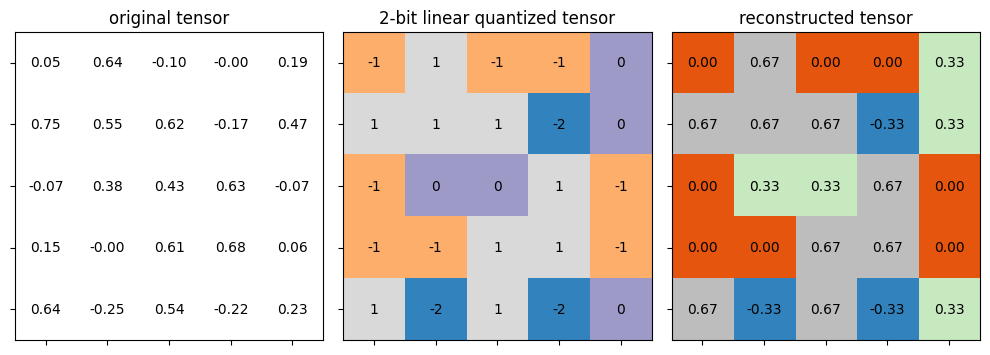

In [18]:
test_linear_quantize()

이제 linear quantization을 위한 scaling factor $S$ 와 zero point $Z$ 을 결정해야 합니다.

[Linear quantization](https://arxiv.org/pdf/1712.05877.pdf) 은 다음과 같이 표현될 수 있습니다:

$r = S(q-Z)$

### Scale

Linear quantization은 floating point range [*fp_min*, *fp_max*] 를 quantized range [*quantized_min*, *quantized_max*] 로 매핑합니다. 즉, 다음과 같이 표현할 수 있습니다:

> $r_{\mathrm{max}} = S(q_{\mathrm{max}}-Z)$
>
> $r_{\mathrm{min}} = S(q_{\mathrm{min}}-Z)$

이 두 방정식을 빼면, $S=(r_{\mathrm{max}} - r_{\mathrm{min}}) / (q_{\mathrm{max}} - q_{\mathrm{min}})$ 를 얻을 수 있습니다.


부동 소수점 텐서 `fp_tensor`의 $r_{\mathrm{min}}$ and  $r_{\mathrm{max}}$ 를 결정하는 데는 여러가지 접근 방법이 있습니다.

*  가장 일반적인 방법은 `fp_tensor`의 최소값과 최대값을 직접 사용하는 것입니다.
*  또 다른 방법은 쿨백-라이블러 발산(Kullback-Leibler-J divergence)을 최소화하여 *fp_max*를 결정하는 것입니다.

### zero point

Scaling factor $S$ 를 결정한 후, $r_{\mathrm{min}}$ 과 $q_{\mathrm{min}}$ 의 관계를 직접 사용하여 zero point $Z$ 를 계산할 수 있습니다.

> $Z = \mathrm{int}(\mathrm{round}(q_{\mathrm{min}} - r_{\mathrm{min}} / S))$

# [실습 2] Scale 및 zero point 계산

부동 소수점 텐서 $r$ 에서 scale $S$ 와 zero point $Z$ 을 계산하는 다음 함수를 완성해 주세요.

In [1]:
def get_quantization_scale_and_zero_point(fp_tensor, bitwidth):
    """
    get quantization scale for single tensor
    :param fp_tensor: [torch.(cuda.)Tensor] floating tensor to be quantized
    :param bitwidth: [int] quantization bit width
    :return:
        [float] scale
        [int] zero_point
    """
    quantized_min, quantized_max = get_quantized_range(bitwidth)
    fp_max = fp_tensor.max().item()
    fp_min = fp_tensor.min().item()

    ############### YOUR CODE STARTS HERE ###############
    # hint: quantized_max - quantized_min = 2 ** bitwith - 1
    scale = (fp_max - fp_min) / (quantized_max - quantized_min)
    zero_point = round(quantized_min - fp_min/scale)
    ############### YOUR CODE ENDS HERE #################

    # clip the zero_point to fall in [quantized_min, quantized_max]
    if zero_point < quantized_min:
        zero_point = quantized_min
    elif zero_point > quantized_max:
        zero_point = quantized_max
    else: # convert from float to int using round()
        zero_point = round(zero_point)
    return scale, int(zero_point)

이제  실습 1의 `linear_quantize()`과 실습 2의 `get_quantization_scale_and_zero_point()`을 하나의 함수로 래핑합니다.

In [2]:
def linear_quantize_feature(fp_tensor, bitwidth):
    """
    linear quantization for feature tensor
    :param fp_tensor: [torch.(cuda.)Tensor] floating feature to be quantized
    :param bitwidth: [int] quantization bit width
    :return:
        [torch.(cuda.)Tensor] quantized tensor
        [float] scale tensor
        [int] zero point
    """
    scale, zero_point = get_quantization_scale_and_zero_point(fp_tensor, bitwidth)
    quantized_tensor = linear_quantize(fp_tensor, bitwidth, scale, zero_point)
    return quantized_tensor, scale, zero_point

## 특수 케이스 : 가중치 텐서의 Linear quantization

먼저 가중치 텐서의 분포를 살펴보겠습니다.

In [3]:
def plot_weight_distribution(model, bitwidth=32):
    # bins = (1 << bitwidth) if bitwidth <= 8 else 256
    if bitwidth <= 8:
        qmin, qmax = get_quantized_range(bitwidth)
        bins = np.arange(qmin, qmax + 2)
        align = 'left'
    else:
        bins = 256
        align = 'mid'
    fig, axes = plt.subplots(3,3, figsize=(10, 6))
    axes = axes.ravel()
    plot_index = 0
    for name, param in model.named_parameters():
        if param.dim() > 1:
            ax = axes[plot_index]
            ax.hist(param.detach().view(-1).cpu(), bins=bins, density=True,
                    align=align, color = 'blue', alpha = 0.5,
                    edgecolor='black' if bitwidth <= 4 else None)
            if bitwidth <= 4:
                quantized_min, quantized_max = get_quantized_range(bitwidth)
                ax.set_xticks(np.arange(start=quantized_min, stop=quantized_max+1))
            ax.set_xlabel(name)
            ax.set_ylabel('density')
            plot_index += 1
    fig.suptitle(f'Histogram of Weights (bitwidth={bitwidth} bits)')
    fig.tight_layout()
    fig.subplots_adjust(top=0.925)
    plt.show()

recover_model()
plot_weight_distribution(model)

NameError: name 'recover_model' is not defined

위의 히스토그램에서 볼 수 있듯이, 가중치 값의 분포는 0을 중심으로 거의 대칭입니다(Classifier 제외).

따라서 일반적으로 가중치를 quantization 할 때 zeropoint $Z$를 0으로 설정합니다.

$r = S(q-Z)$ 로 부터, 우리는 다음을 도출 할 수 있습니다:

> $r_{\mathrm{max}} = S \cdot q_{\mathrm{max}}$

그러므로

> $S = r_{\mathrm{max}} / q_{\mathrm{max}}$

가중치 값의 최대 크기를 $r_{\mathrm{max}}$로 직접 사용합니다.

In [22]:
def get_quantization_scale_for_weight(weight, bitwidth):
    """
    get quantization scale for single tensor of weight
    :param weight: [torch.(cuda.)Tensor] floating weight to be quantized
    :param bitwidth: [integer] quantization bit width
    :return:
        [floating scalar] scale
    """
    # 가중치 텐서의 분포가 대칭이라고 가정합니다.
    # zeropoint를 0으로 설정합니다.
    fp_max = max(weight.abs().max().item(), 5e-7)
    _, quantized_max = get_quantized_range(bitwidth)
    return fp_max / quantized_max

### Per-tensor Linear Quantization

먼저 가장 기초적인 방법인 Per-Tensor Quantization을 적용해보겠습니다.

Per-Tensor Quantization은 weight tensor $W$ 에 대해서 하나의 scaling factors $S$ 와 zero points $Z$를 결정합니다.

Per-Tensor Quantization은 구현이 쉽고 연산량이 적으며, 크기가 큰 모델에서 잘 작동합니다.

In [23]:
def linear_quantize_weight_per_tensor(tensor, bitwidth):
    """
    linear quantization for weight tensor
        using different scales and zero_points for different output channels
    :param tensor: [torch.(cuda.)Tensor] floating weight to be quantized
    :param bitwidth: [int] quantization bit width
    :return:
        [torch.(cuda.)Tensor] quantized tensor
        [torch.(cuda.)Tensor] scale tensor
        [int] zero point (which is always 0)
    """
    scale_value = get_quantization_scale_for_weight(tensor, bitwidth)

    scale = torch.tensor([scale_value], device=tensor.device)

    scale_shape = [1] * tensor.dim()
    scale_shape[0] = tensor.shape[0]
    scale_per_channel = scale.expand(scale_shape)
    quantized_tensor = linear_quantize(tensor, bitwidth, scale_per_channel, zero_point=0)

    return quantized_tensor, scale_per_channel, 0

### Per-channel Linear Quantization

2D convolution의 경우, 가중치 텐서는 (num_output_channels, num_input_channels, kernel_height, kernel_width) 형태의 4D tensor 입니다.

최근 연구에서는, 서로 다른 출력 채널에 대해 다른 scaling factors $S$ 와 zero points $Z$ 를 사용하는 것이 더 나은 성능을 발휘한다는 것을 보여줍니다.

따라서 각 출력 채널의 부분 텐서에 대한 scaling factor $S$ 와 zero point $Z$ 을 독립적으로 결정해야 합니다.

In [24]:
def linear_quantize_weight_per_channel(tensor, bitwidth):
    """
    linear quantization for weight tensor
        using different scales and zero_points for different output channels
    :param tensor: [torch.(cuda.)Tensor] floating weight to be quantized
    :param bitwidth: [int] quantization bit width
    :return:
        [torch.(cuda.)Tensor] quantized tensor
        [torch.(cuda.)Tensor] scale tensor
        [int] zero point (which is always 0)
    """
    dim_output_channels = 0
    num_output_channels = tensor.shape[dim_output_channels]
    scale = torch.zeros(num_output_channels, device=tensor.device)

    for oc in range(num_output_channels):
        _subtensor = tensor.select(dim_output_channels, oc)
        _scale = get_quantization_scale_for_weight(_subtensor, bitwidth)
        scale[oc] = _scale
    scale_shape = [1] * tensor.dim()
    scale_shape[dim_output_channels] = -1
    scale = scale.view(scale_shape)
    quantized_tensor = linear_quantize(tensor, bitwidth, scale, zero_point=0)
    return quantized_tensor, scale, 0

이제 서로 4-bit 비트 폭으로 가중치에 per-tensor와 per-channel linear quantization을 각각 적용할 때의 가중치 분포를 살펴보겠습니다.

Per-Tensor Quantization:


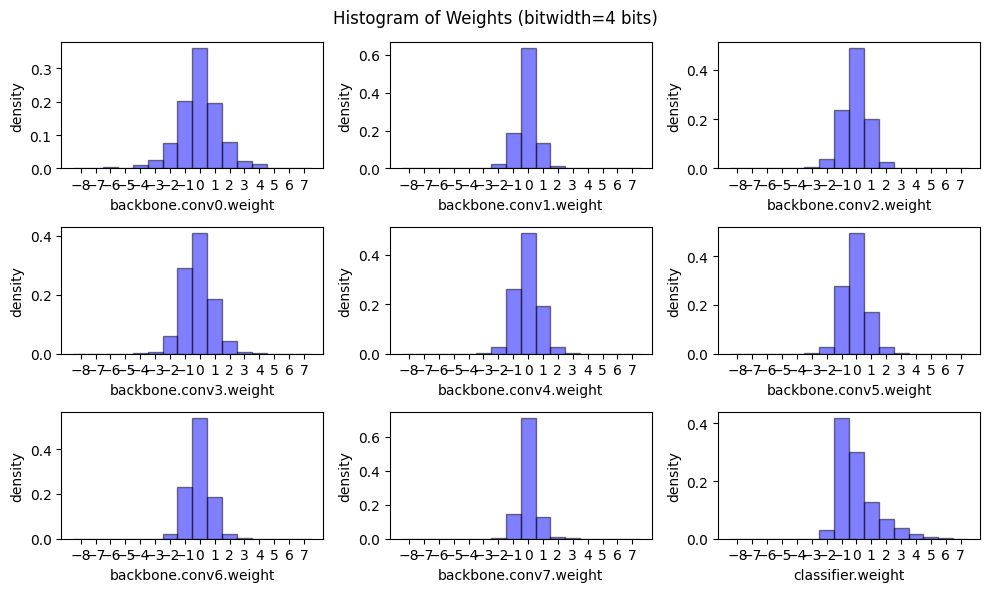

Per-Channel Quantization:


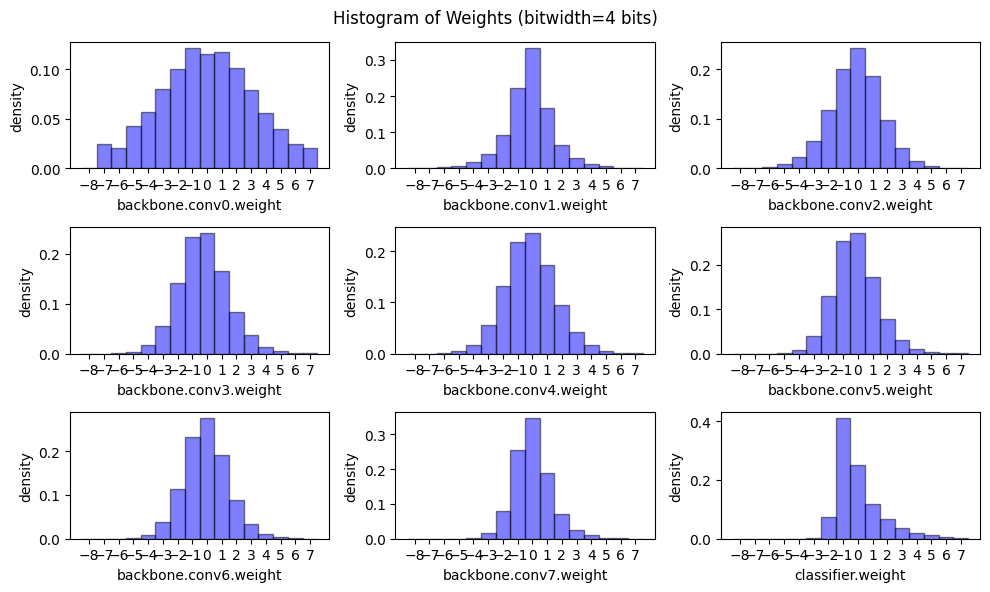

In [25]:
@torch.no_grad()
def peek_linear_quantization_per_tensor():
    for bitwidth in [4]:
        for name, param in model.named_parameters():
            if param.dim() > 1:
                quantized_param, scale, zero_point = \
                    linear_quantize_weight_per_tensor(param, bitwidth)
                param.copy_(quantized_param)
        plot_weight_distribution(model, bitwidth)
        recover_model()
print("Per-Tensor Quantization:")
peek_linear_quantization_per_tensor()

@torch.no_grad()
def peek_linear_quantization_per_channel():
    for bitwidth in [4]:
        for name, param in model.named_parameters():
            if param.dim() > 1:
                quantized_param, scale, zero_point = \
                    linear_quantize_weight_per_channel(param, bitwidth)
                param.copy_(quantized_param)
        plot_weight_distribution(model, bitwidth)
        recover_model()
print("Per-Channel Quantization:")
peek_linear_quantization_per_channel()

per-tensor와 per-channel linear quantization을 적용했을 때 weight 분포의 차이를 살펴볼 수 있습니다.

## Quantized Inference

Quantization 후에는 convolution layer 및 fully-connected layer 에서의 추론 방식도 변경됩니다.

$r = S(q-Z)$ 이므로,

> $r_{\mathrm{input}} = S_{\mathrm{input}}(q_{\mathrm{input}}-Z_{\mathrm{input}})$
>
> $r_{\mathrm{weight}} = S_{\mathrm{weight}}(q_{\mathrm{weight}}-Z_{\mathrm{weight}})$
>
> $r_{\mathrm{bias}} = S_{\mathrm{bias}}(q_{\mathrm{bias}}-Z_{\mathrm{bias}})$

여기서 $Z_{\mathrm{weight}}=0$, $r_{\mathrm{weight}} = S_{\mathrm{weight}}q_{\mathrm{weight}}$ 입니다.

&nbsp;

부동 소수점 convolution은 다음과 같이 쓸 수 있습니다:

> $r_{\mathrm{output}} = \mathrm{CONV}[r_{\mathrm{input}}, r_{\mathrm{weight}}] + r_{\mathrm{bias}}\\
\;\;\;\;\;\;\;\;\;\;= \mathrm{CONV}[S_{\mathrm{input}}(q_{\mathrm{input}}-Z_{\mathrm{input}}), S_{\mathrm{weight}}q_{\mathrm{weight}}] + S_{\mathrm{bias}}(q_{\mathrm{bias}}-Z_{\mathrm{bias}})\\
\;\;\;\;\;\;\;\;\;\;= \mathrm{CONV}[q_{\mathrm{input}}-Z_{\mathrm{input}}, q_{\mathrm{weight}}]\cdot (S_{\mathrm{input}} \cdot S_{\mathrm{weight}}) + S_{\mathrm{bias}}(q_{\mathrm{bias}}-Z_{\mathrm{bias}})$

계산을 더욱 간단히 하기 위하여, 다음과 같이 나타낼 수 있습니다:

> $Z_{\mathrm{bias}} = 0$
>
> $S_{\mathrm{bias}} = S_{\mathrm{input}} \cdot S_{\mathrm{weight}}$

그러므로

> $r_{\mathrm{output}} = (\mathrm{CONV}[q_{\mathrm{input}}-Z_{\mathrm{input}}, q_{\mathrm{weight}}] + q_{\mathrm{bias}})\cdot (S_{\mathrm{input}} \cdot S_{\mathrm{weight}})$
>
> $\;\;\;\;\;\;\;\;= (\mathrm{CONV}[q_{\mathrm{input}}, q_{\mathrm{weight}}] - \mathrm{CONV}[Z_{\mathrm{input}}, q_{\mathrm{weight}}] + q_{\mathrm{bias}})\cdot (S_{\mathrm{input}}S_{\mathrm{weight}})$

> $r_{\mathrm{output}} = S_{\mathrm{output}}(q_{\mathrm{output}}-Z_{\mathrm{output}})$

> $S_{\mathrm{output}}(q_{\mathrm{output}}-Z_{\mathrm{output}}) = (\mathrm{CONV}[q_{\mathrm{input}}, q_{\mathrm{weight}}] - \mathrm{CONV}[Z_{\mathrm{input}}, q_{\mathrm{weight}}] + q_{\mathrm{bias}})\cdot (S_{\mathrm{input}} S_{\mathrm{weight}})$

> $q_{\mathrm{output}} = (\mathrm{CONV}[q_{\mathrm{input}}, q_{\mathrm{weight}}] - \mathrm{CONV}[Z_{\mathrm{input}}, q_{\mathrm{weight}}] + q_{\mathrm{bias}})\cdot (S_{\mathrm{input}}S_{\mathrm{weight}} / S_{\mathrm{output}}) + Z_{\mathrm{output}}$

$Z_{\mathrm{input}}$, $q_{\mathrm{weight}}$, $q_{\mathrm{bias}}$ 는 추론 전에 결정되므로,

> $Q_{\mathrm{bias}} = q_{\mathrm{bias}} - \mathrm{CONV}[Z_{\mathrm{input}}, q_{\mathrm{weight}}]$

&nbsp;

즉 quantized convolution은 다음과 같이 쓸 수 있습니다:

> $q_{\mathrm{output}} = (\mathrm{CONV}[q_{\mathrm{input}}, q_{\mathrm{weight}}] + Q_{\mathrm{bias}}) \cdot (S_{\mathrm{input}}S_{\mathrm{weight}} / S_{\mathrm{output}}) + Z_{\mathrm{output}}$

&nbsp;

비슷하게, quantized fully-connected layer는 다음과 같이 쓸 수 있습니다:

> $q_{\mathrm{output}} = (\mathrm{Linear}[q_{\mathrm{input}}, q_{\mathrm{weight}}] + Q_{\mathrm{bias}})\cdot (S_{\mathrm{input}} \cdot S_{\mathrm{weight}} / S_{\mathrm{output}}) + Z_{\mathrm{output}}$

여기서

> $Q_{\mathrm{bias}} = q_{\mathrm{bias}} - \mathrm{Linear}[Z_{\mathrm{input}}, q_{\mathrm{weight}}]$

또한 위의 추론에 따라, Bias는 다음과 같이 linear quantization 됩니다.

> $Z_{\mathrm{bias}} = 0$
>
> $S_{\mathrm{bias}} = S_{\mathrm{input}} \cdot S_{\mathrm{weight}}$

In [26]:
def linear_quantize_bias_per_output_channel(bias, weight_scale, input_scale):
    """
    linear quantization for single bias tensor
        quantized_bias = fp_bias / bias_scale
    :param bias: [torch.FloatTensor] bias weight to be quantized
    :param weight_scale: [float or torch.FloatTensor] weight scale tensor
    :param input_scale: [float] input scale
    :return:
        [torch.IntTensor] quantized bias tensor
    """
    assert(bias.dim() == 1)
    assert(bias.dtype == torch.float)
    assert(isinstance(input_scale, float))
    if isinstance(weight_scale, torch.Tensor):
        assert(weight_scale.dtype == torch.float)
        weight_scale = weight_scale.view(-1)
        assert(bias.numel() == weight_scale.numel())

    bias_scale = input_scale * weight_scale

    quantized_bias = linear_quantize(bias, 32, bias_scale, zero_point=0, dtype=torch.int32)
    return quantized_bias, bias_scale, 0

## Quantized Fully-Connected Layer

Quantized fully-connected layer의 경우, 먼저 $Q_{\mathrm{bias}}$ 을 미리 계산합니다.

$Q_{\mathrm{bias}} = q_{\mathrm{bias}} - \mathrm{Linear}[Z_{\mathrm{input}}, q_{\mathrm{weight}}]$ 라는 것을 참고하세요.

In [27]:
def shift_quantized_linear_bias(quantized_bias, quantized_weight, input_zero_point):
    """
    shift quantized bias to incorporate input_zero_point for nn.Linear
        shifted_quantized_bias = quantized_bias - Linear(input_zero_point, quantized_weight)
    :param quantized_bias: [torch.IntTensor] quantized bias (torch.int32)
    :param quantized_weight: [torch.CharTensor] quantized weight (torch.int8)
    :param input_zero_point: [int] input zero point
    :return:
        [torch.IntTensor] shifted quantized bias tensor
    """
    assert(quantized_bias.dtype == torch.int32)
    assert(isinstance(input_zero_point, int))
    return quantized_bias - quantized_weight.sum(1).to(torch.int32) * input_zero_point

# [실습 3] Quantized FC layer 구현

Quantized fully-connected layer를 추론하기 위해 다음 함수를 완성해 주세요.

**Hint**:

> $q_{\mathrm{output}} = (\mathrm{Linear}[q_{\mathrm{input}}, q_{\mathrm{weight}}] + Q_{\mathrm{bias}})\cdot (S_{\mathrm{input}} S_{\mathrm{weight}} / S_{\mathrm{output}}) + Z_{\mathrm{output}}$

In [28]:
def quantized_linear(input, weight, bias, feature_bitwidth, weight_bitwidth,
                     input_zero_point, output_zero_point,
                     input_scale, weight_scale, output_scale):
    """
    quantized fully-connected layer
    :param input: [torch.CharTensor] quantized input (torch.int8)
    :param weight: [torch.CharTensor] quantized weight (torch.int8)
    :param bias: [torch.IntTensor] shifted quantized bias or None (torch.int32)
    :param feature_bitwidth: [int] quantization bit width of input and output
    :param weight_bitwidth: [int] quantization bit width of weight
    :param input_zero_point: [int] input zero point
    :param output_zero_point: [int] output zero point
    :param input_scale: [float] input feature scale
    :param weight_scale: [torch.FloatTensor] weight per-channel scale
    :param output_scale: [float] output feature scale
    :return:
        [torch.CharIntTensor] quantized output feature (torch.int8)
    """
    assert(input.dtype == torch.int8)
    assert(weight.dtype == input.dtype)
    assert(bias is None or bias.dtype == torch.int32)
    assert(isinstance(input_zero_point, int))
    assert(isinstance(output_zero_point, int))
    assert(isinstance(input_scale, float))
    assert(isinstance(output_scale, float))
    assert(weight_scale.dtype == torch.float)

    # Step 1: integer-based fully-connected (8-bit multiplication with 32-bit accumulation)
    if 'cpu' in input.device.type:
        # use 32-b MAC for simplicity
        output = torch.nn.functional.linear(input.to(torch.int32), weight.to(torch.int32), bias)
    else:
        # 현재 버전의 PyTorch는 GPU에서 정수 기반의 linear() 연산을 아직 지원하지 않습니다.
        output = torch.nn.functional.linear(input.float(), weight.float(), bias.float())

    # weight scale의 shape 가[oc, 1, 1, 1] 인 반면, output의 shape는 [batch_size, oc]이므로 shape를 조정합니다.
    weight_scale = weight_scale.flatten().view(1, -1)

    # scale이 부동 소수점이므로, 출력도 부동 소수점으로 변환해야 합니다.
    output = output.float()

    ############### YOUR CODE STARTS HERE ###############
    # Step 2: output 텐서를 scale합니다.
    output = output*(input_scale * weight_scale / output_scale)

    # Step 3: output을 out_zero_point 만큼 이동하여 영점을 조정합니다.
    output = output + output_zero_point
    ############### YOUR CODE ENDS HERE #################

    # 모든 값이 지정된 비트폭 범위 내에 있도록 clamp합니다.
    output = output.round().clamp(*get_quantized_range(feature_bitwidth)).to(torch.int8)
    return output

Quantized fully connected layer 함수의 동작을 검증해보겠습니다.

In [29]:
def test_quantized_fc(
    input=torch.tensor([
        [0.6118, 0.7288, 0.8511, 0.2849, 0.8427, 0.7435, 0.4014, 0.2794],
        [0.3676, 0.2426, 0.1612, 0.7684, 0.6038, 0.0400, 0.2240, 0.4237],
        [0.6565, 0.6878, 0.4670, 0.3470, 0.2281, 0.8074, 0.0178, 0.3999],
        [0.1863, 0.3567, 0.6104, 0.0497, 0.0577, 0.2990, 0.6687, 0.8626]]),
    weight=torch.tensor([
        [ 1.2626e-01, -1.4752e-01,  8.1910e-02,  2.4982e-01, -1.0495e-01,
         -1.9227e-01, -1.8550e-01, -1.5700e-01],
        [ 2.7624e-01, -4.3835e-01,  5.1010e-02, -1.2020e-01, -2.0344e-01,
          1.0202e-01, -2.0799e-01,  2.4112e-01],
        [-3.8216e-01, -2.8047e-01,  8.5238e-02, -4.2504e-01, -2.0952e-01,
          3.2018e-01, -3.3619e-01,  2.0219e-01],
        [ 8.9233e-02, -1.0124e-01,  1.1467e-01,  2.0091e-01,  1.1438e-01,
         -4.2427e-01,  1.0178e-01, -3.0941e-04],
        [-1.8837e-02, -2.1256e-01, -4.5285e-01,  2.0949e-01, -3.8684e-01,
         -1.7100e-01, -4.5331e-01, -2.0433e-01],
        [-2.0038e-01, -5.3757e-02,  1.8997e-01, -3.6866e-01,  5.5484e-02,
          1.5643e-01, -2.3538e-01,  2.1103e-01],
        [-2.6875e-01,  2.4984e-01, -2.3514e-01,  2.5527e-01,  2.0322e-01,
          3.7675e-01,  6.1563e-02,  1.7201e-01],
        [ 3.3541e-01, -3.3555e-01, -4.3349e-01,  4.3043e-01, -2.0498e-01,
         -1.8366e-01, -9.1553e-02, -4.1168e-01]]),
    bias=torch.tensor([ 0.1954, -0.2756,  0.3113,  0.1149,  0.4274,  0.2429, -0.1721, -0.2502]),
    quantized_bias=torch.tensor([ 3, -2,  3,  1,  3,  2, -2, -2], dtype=torch.int32),
    shifted_quantized_bias=torch.tensor([-1,  0, -3, -1, -3,  0,  2, -4], dtype=torch.int32),
    calc_quantized_output=torch.tensor([
        [ 0, -1,  0, -1, -1,  0,  1, -2],
        [ 0,  0, -1,  0,  0,  0,  0, -1],
        [ 0,  0,  0, -1,  0,  0,  0, -1],
        [ 0,  0,  0,  0,  0,  1, -1, -2]], dtype=torch.int8),
    bitwidth=2, batch_size=4, in_channels=8, out_channels=8):
    def plot_matrix(tensor, ax, title, vmin=0, vmax=1, cmap=ListedColormap(['white'])):
        ax.imshow(tensor.cpu().numpy(), vmin=vmin, vmax=vmax, cmap=cmap)
        ax.set_title(title)
        ax.set_yticklabels([])
        ax.set_xticklabels([])
        for i in range(tensor.shape[0]):
            for j in range(tensor.shape[1]):
                datum = tensor[i, j].item()
                if isinstance(datum, float):
                    text = ax.text(j, i, f'{datum:.2f}',
                                    ha="center", va="center", color="k")
                else:
                    text = ax.text(j, i, f'{datum}',
                                    ha="center", va="center", color="k")

    output = torch.nn.functional.linear(input, weight, bias)

    quantized_weight, weight_scale, weight_zero_point = \
        linear_quantize_weight_per_channel(weight, bitwidth)
    quantized_input, input_scale, input_zero_point = \
        linear_quantize_feature(input, bitwidth)
    _quantized_bias, bias_scale, bias_zero_point = \
        linear_quantize_bias_per_output_channel(bias, weight_scale, input_scale)


    assert _quantized_bias.equal(quantized_bias) # original: _quantized_bias.equal(_quantized_bias)
    _shifted_quantized_bias = \
        shift_quantized_linear_bias(quantized_bias, quantized_weight, input_zero_point)
    assert _shifted_quantized_bias.equal(shifted_quantized_bias)
    quantized_output, output_scale, output_zero_point = \
        linear_quantize_feature(output, bitwidth)

    _calc_quantized_output = quantized_linear(
        quantized_input, quantized_weight, shifted_quantized_bias,
        bitwidth, bitwidth,
        input_zero_point, output_zero_point,
        input_scale, weight_scale, output_scale)

    assert _calc_quantized_output.equal(calc_quantized_output)

    reconstructed_weight = weight_scale * (quantized_weight.float() - weight_zero_point)
    reconstructed_input = input_scale * (quantized_input.float() - input_zero_point)
    reconstructed_bias = bias_scale * (quantized_bias.float() - bias_zero_point)
    reconstructed_calc_output = output_scale * (calc_quantized_output.float() - output_zero_point)

    fig, axes = plt.subplots(3,3, figsize=(15, 12))
    quantized_min, quantized_max = get_quantized_range(bitwidth)
    plot_matrix(weight, axes[0, 0], 'original weight', vmin=-0.5, vmax=0.5)
    plot_matrix(input.t(), axes[1, 0], 'original input', vmin=0, vmax=1)
    plot_matrix(output.t(), axes[2, 0], 'original output', vmin=-1.5, vmax=1.5)
    plot_matrix(quantized_weight, axes[0, 1], f'{bitwidth}-bit linear quantized weight',
                vmin=quantized_min, vmax=quantized_max, cmap='tab20c')
    plot_matrix(quantized_input.t(), axes[1, 1], f'{bitwidth}-bit linear quantized input',
                vmin=quantized_min, vmax=quantized_max, cmap='tab20c')
    plot_matrix(calc_quantized_output.t(), axes[2, 1], f'quantized output from quantized_linear()',
                vmin=quantized_min, vmax=quantized_max, cmap='tab20c')
    plot_matrix(reconstructed_weight, axes[0, 2], f'reconstructed weight',
                vmin=-0.5, vmax=0.5, cmap='tab20c')
    plot_matrix(reconstructed_input.t(), axes[1, 2], f'reconstructed input',
                vmin=0, vmax=1, cmap='tab20c')
    plot_matrix(reconstructed_calc_output.t(), axes[2, 2], f'reconstructed output',
                vmin=-1.5, vmax=1.5, cmap='tab20c')

    print('* Test quantized_fc()')
    print(f'    target bitwidth: {bitwidth} bits')
    print(f'      batch size: {batch_size}')
    print(f'      input channels: {in_channels}')
    print(f'      output channels: {out_channels}')
    print('* Test passed.')
    fig.tight_layout()
    plt.show()

* Test quantized_fc()
    target bitwidth: 2 bits
      batch size: 4
      input channels: 8
      output channels: 8
* Test passed.


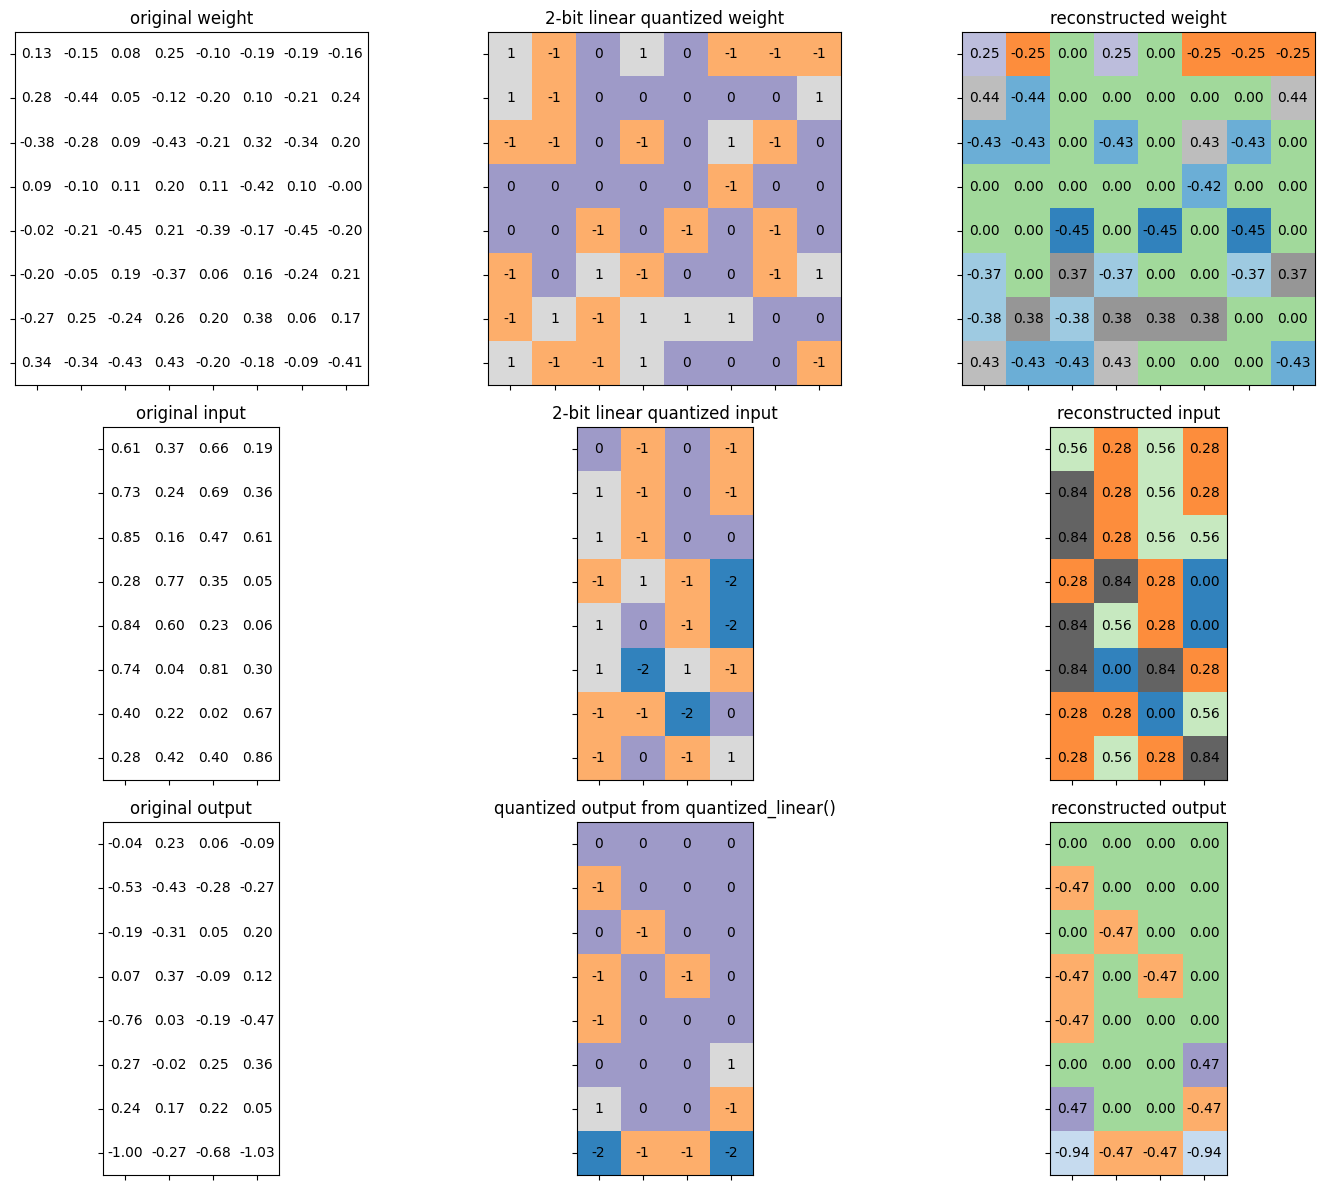

In [30]:
test_quantized_fc()

## Quantized Convolution Layer

Quantized convolution layer의 경우, 먼저 $Q_{\mathrm{bias}}$ 을 미리 계산합니다.

$Q_{\mathrm{bias}} = q_{\mathrm{bias}} - \mathrm{CONV}[Z_{\mathrm{input}}, q_{\mathrm{weight}}]$ 라는 것을 참고하세요.

In [31]:
def shift_quantized_conv2d_bias(quantized_bias, quantized_weight, input_zero_point):
    """
    shift quantized bias to incorporate input_zero_point for nn.Conv2d
        shifted_quantized_bias = quantized_bias - Conv(input_zero_point, quantized_weight)
    :param quantized_bias: [torch.IntTensor] quantized bias (torch.int32)
    :param quantized_weight: [torch.CharTensor] quantized weight (torch.int8)
    :param input_zero_point: [int] input zero point
    :return:
        [torch.IntTensor] shifted quantized bias tensor
    """
    assert(quantized_bias.dtype == torch.int32)
    assert(isinstance(input_zero_point, int))
    return quantized_bias - quantized_weight.sum((1,2,3)).to(torch.int32) * input_zero_point

# [실습 3] Quantized convolution layer 구현

Quantized convolution layer를 추론하기 위해 다음 함수를 완성해 주세요.

**Hint**:
> $q_{\mathrm{output}} = (\mathrm{CONV}[q_{\mathrm{input}}, q_{\mathrm{weight}}] + Q_{\mathrm{bias}}) \cdot (S_{\mathrm{input}}S_{\mathrm{weight}} / S_{\mathrm{output}}) + Z_{\mathrm{output}}$


In [32]:
def quantized_conv2d(input, weight, bias, feature_bitwidth, weight_bitwidth,
                     input_zero_point, output_zero_point,
                     input_scale, weight_scale, output_scale,
                     stride, padding, dilation, groups):
    """
    quantized 2d convolution
    :param input: [torch.CharTensor] quantized input (torch.int8)
    :param weight: [torch.CharTensor] quantized weight (torch.int8)
    :param bias: [torch.IntTensor] shifted quantized bias or None (torch.int32)
    :param feature_bitwidth: [int] quantization bit width of input and output
    :param weight_bitwidth: [int] quantization bit width of weight
    :param input_zero_point: [int] input zero point
    :param samp: [int] output zero point
    :param input_scale: [float] input feature scale
    :param weight_scale: [torch.FloatTensor] weight per-channel scale
    :param output_scale: [float] output feature scale
    :return:
        [torch.(cuda.)CharTensor] quantized output feature
    """
    assert(len(padding) == 4)
    assert(input.dtype == torch.int8)
    assert(weight.dtype == input.dtype)
    assert(bias is None or bias.dtype == torch.int32)
    assert(isinstance(input_zero_point, int))
    assert(isinstance(output_zero_point, int))
    assert(isinstance(input_scale, float))
    assert(isinstance(output_scale, float))
    assert(weight_scale.dtype == torch.float)

    # Step 1: calculate integer-based 2d convolution (8-bit multiplication with 32-bit accumulation)
    input = torch.nn.functional.pad(input, padding, 'constant', input_zero_point)
    if 'cpu' in input.device.type:
        # use 32-b MAC for simplicity
        output = torch.nn.functional.conv2d(input.to(torch.int32), weight.to(torch.int32), None, stride, 0, dilation, groups)
    else:
        # 현재 버전의 PyTorch는 GPU에서 정수 기반의 conv2d() 연산을 아직 지원하지 않습니다.
        output = torch.nn.functional.conv2d(input.float(), weight.float(), None, stride, 0, dilation, groups)
        output = output.round().to(torch.int32)
    if bias is not None:
        output = output + bias.view(1, -1, 1, 1)


    # weight scale의 shape가 [oc, 1, 1, 1]인 반면, output의 shape는 [batch_size, oc, height, width]이므로 shape를 조정합니다.
    weight_scale = weight_scale.flatten().view(1, -1, 1, 1)

    # scale이 부동 소수점이므로, 출력도 부동 소수점으로 변환해야 합니다.
    output = output.float()

    ############### YOUR CODE STARTS HERE ###############
    # hint: 이번 코드 블록은 quantized_linear()와 매우 유사합니다.

    # Step 2: output 텐서를 scale합니다.
    output = output*(input_scale * weight_scale / output_scale)

    # Step 3: output을 out_zero_point 만큼 이동하여 영점을 조정합니다.
    output = output + output_zero_point
    ############### YOUR CODE ENDS HERE #################

    # 모든 값이 지정된 비트폭 범위 내에 있도록 clamp 합니다.
    output = output.round().clamp(*get_quantized_range(feature_bitwidth)).to(torch.int8)
    return output

# Quantized inference 수행

마지막으로 모든 것을 결합하여 모델에 대해 post-training int8 quantization을 수행합니다.

모델의 convolution layer과 fully-connected layer를 하나씩 quantized 버전으로 변환할 것입니다.

1. Quantization 전에 이전의 convolution layer에 BatchNorm layer을 융합(fuse)할 것입니다. 이는 quantization 전에 일반적으로 수행되는 표준 관행입니다. BatchNorm을 융합하면 추론 중에 추가적인 곱셈 연산이 줄어듭니다.


또한, 융합된 모델 `model_fused` 가 원래 모델과 동일한 정확도를 가지는지 확인할 것입니다(BatchNorm fusion은 네트워크 기능을 변경하지 않는 동등한 변환입니다).

In [33]:
def fuse_conv_bn(conv, bn):
    # modified from https://mmcv.readthedocs.io/en/latest/_modules/mmcv/cnn/utils/fuse_conv_bn.html
    assert conv.bias is None

    factor = bn.weight.data / torch.sqrt(bn.running_var.data + bn.eps)
    conv.weight.data = conv.weight.data * factor.reshape(-1, 1, 1, 1)
    conv.bias = nn.Parameter(- bn.running_mean.data * factor + bn.bias.data)

    return conv

print('Before conv-bn fusion: backbone length', len(model.backbone))
#  batchnorm 을 conv layer로 fusion 합니다.
recover_model()
model_fused = copy.deepcopy(model)
fused_backbone = []
ptr = 0
while ptr < len(model_fused.backbone):
    if isinstance(model_fused.backbone[ptr], nn.Conv2d) and \
        isinstance(model_fused.backbone[ptr + 1], nn.BatchNorm2d):
        fused_backbone.append(fuse_conv_bn(
            model_fused.backbone[ptr], model_fused.backbone[ptr+ 1]))
        ptr += 2
    else:
        fused_backbone.append(model_fused.backbone[ptr])
        ptr += 1
model_fused.backbone = nn.Sequential(*fused_backbone)

print('After conv-bn fusion: backbone length', len(model_fused.backbone))
# sanity check, no BN anymore
for m in model_fused.modules():
    assert not isinstance(m, nn.BatchNorm2d)

#  정확도는 동일해야합니다.
fused_acc = evaluate(model_fused, dataloader['test'])
print(f'Accuracy of the fused model={fused_acc:.2f}%')

Before conv-bn fusion: backbone length 29
After conv-bn fusion: backbone length 21


eval:   0%|          | 0/1 [00:00<?, ?it/s]

Accuracy of the fused model=93.00%


2. 샘플 데이터를 사용하여 모델을 실행하여 각 featuremap의 range를 얻을 것입니다. 이렇게 하면 featuremap의 range를 파악하고 해당하는 scaling factor와 zero point를 계산할 수 있습니다.

In [34]:
# add hook to record the min max value of the activation
input_activation = {}
output_activation = {}

def add_range_recoder_hook(model):
    import functools
    def _record_range(self, x, y, module_name):
        x = x[0]
        input_activation[module_name] = x.detach()
        output_activation[module_name] = y.detach()

    all_hooks = []
    for name, m in model.named_modules():
        if isinstance(m, (nn.Conv2d, nn.Linear, nn.ReLU)):
            all_hooks.append(m.register_forward_hook(
                functools.partial(_record_range, module_name=name)))
    return all_hooks

hooks = add_range_recoder_hook(model_fused)
# 훈련 데이터에서 샘플을 추출하고, 추론에 사용할 scale과 zero point를 얻습니다.
sample_data = iter(dataloader['train']).__next__()[0].to(model_device(model_fused))
model_fused(sample_data)

# remove hooks
for h in hooks:
    h.remove()

3. 마지막으로 quantization을 수행하겠습니다. 다음 매핑에 따라 모델을 변환할 것입니다.
```python
nn.Conv2d: QuantizedConv2d,
nn.Linear: QuantizedLinear,
# 아래 두 함수는 단순한 래퍼입니다.
# torch modules 은 아직 int8 데이터 포맷을 지원하지 않습니다.
# 계산을 위해 임시로 이 값을 FP32로 변환할 것입니다.
nn.MaxPool2d: QuantizedMaxPool2d,
nn.AvgPool2d: QuantizedAvgPool2d,
```

In [35]:
class QuantizedConv2d(nn.Module):
    def __init__(self, weight, bias,
                 input_zero_point, output_zero_point,
                 input_scale, weight_scale, output_scale,
                 stride, padding, dilation, groups,
                 feature_bitwidth=8, weight_bitwidth=8):
        super().__init__()
        # 현재 버전의 PyTorch는 IntTensor를 nn.Parameter로 지원하지 않습니다.
        self.register_buffer('weight', weight)
        self.register_buffer('bias', bias)

        self.input_zero_point = input_zero_point
        self.output_zero_point = output_zero_point

        self.input_scale = input_scale
        self.register_buffer('weight_scale', weight_scale)
        self.output_scale = output_scale

        self.stride = stride
        self.padding = (padding[1], padding[1], padding[0], padding[0])
        self.dilation = dilation
        self.groups = groups

        self.feature_bitwidth = feature_bitwidth
        self.weight_bitwidth = weight_bitwidth


    def forward(self, x):
        return quantized_conv2d(
            x, self.weight, self.bias,
            self.feature_bitwidth, self.weight_bitwidth,
            self.input_zero_point, self.output_zero_point,
            self.input_scale, self.weight_scale, self.output_scale,
            self.stride, self.padding, self.dilation, self.groups
            )

class QuantizedLinear(nn.Module):
    def __init__(self, weight, bias,
                 input_zero_point, output_zero_point,
                 input_scale, weight_scale, output_scale,
                 feature_bitwidth=8, weight_bitwidth=8):
        super().__init__()
        # 현재 버전의 PyTorch는 IntTensor를 nn.Parameter로 지원하지 않습니다.
        self.register_buffer('weight', weight)
        self.register_buffer('bias', bias)

        self.input_zero_point = input_zero_point
        self.output_zero_point = output_zero_point

        self.input_scale = input_scale
        self.register_buffer('weight_scale', weight_scale)
        self.output_scale = output_scale

        self.feature_bitwidth = feature_bitwidth
        self.weight_bitwidth = weight_bitwidth

    def forward(self, x):
        return quantized_linear(
            x, self.weight, self.bias,
            self.feature_bitwidth, self.weight_bitwidth,
            self.input_zero_point, self.output_zero_point,
            self.input_scale, self.weight_scale, self.output_scale
            )

class QuantizedMaxPool2d(nn.MaxPool2d):
    def forward(self, x):
        # 현재 버전의 PyTorch는 정수 기반의 MaxPool 연산을 지원하지 않습니다.
        return super().forward(x.float()).to(torch.int8)

class QuantizedAvgPool2d(nn.AvgPool2d):
    def forward(self, x):
        # 현재 버전의 PyTorch는 정수 기반의 AvgPool 연산을 지원하지 않습니다.
        return super().forward(x.float()).to(torch.int8)

feature_bitwidth = weight_bitwidth = 8
quantized_model = copy.deepcopy(model_fused)
quantized_backbone = []
ptr = 0
while ptr < len(quantized_model.backbone):
    if isinstance(quantized_model.backbone[ptr], nn.Conv2d) and \
        isinstance(quantized_model.backbone[ptr + 1], nn.ReLU):
        conv = quantized_model.backbone[ptr]
        conv_name = f'backbone.{ptr}'
        relu = quantized_model.backbone[ptr + 1]
        relu_name = f'backbone.{ptr + 1}'

        input_scale, input_zero_point = \
            get_quantization_scale_and_zero_point(
                input_activation[conv_name], feature_bitwidth)

        output_scale, output_zero_point = \
            get_quantization_scale_and_zero_point(
                output_activation[relu_name], feature_bitwidth)

        quantized_weight, weight_scale, weight_zero_point = \
            linear_quantize_weight_per_tensor(conv.weight.data, weight_bitwidth)
        quantized_bias, bias_scale, bias_zero_point = \
            linear_quantize_bias_per_output_channel(
                conv.bias.data, weight_scale, input_scale)
        shifted_quantized_bias = \
            shift_quantized_conv2d_bias(quantized_bias, quantized_weight,
                                        input_zero_point)

        quantized_conv = QuantizedConv2d(
            quantized_weight, shifted_quantized_bias,
            input_zero_point, output_zero_point,
            input_scale, weight_scale, output_scale,
            conv.stride, conv.padding, conv.dilation, conv.groups,
            feature_bitwidth=feature_bitwidth, weight_bitwidth=weight_bitwidth
        )

        quantized_backbone.append(quantized_conv)
        ptr += 2
    elif isinstance(quantized_model.backbone[ptr], nn.MaxPool2d):
        quantized_backbone.append(QuantizedMaxPool2d(
            kernel_size=quantized_model.backbone[ptr].kernel_size,
            stride=quantized_model.backbone[ptr].stride
            ))
        ptr += 1
    elif isinstance(quantized_model.backbone[ptr], nn.AvgPool2d):
        quantized_backbone.append(QuantizedAvgPool2d(
            kernel_size=quantized_model.backbone[ptr].kernel_size,
            stride=quantized_model.backbone[ptr].stride
            ))
        ptr += 1
    else:
        raise NotImplementedError(type(quantized_model.backbone[ptr]))  # should not happen
quantized_model.backbone = nn.Sequential(*quantized_backbone)

# finally, quantized the classifier
fc_name = 'classifier'
fc = model.classifier
input_scale, input_zero_point = \
    get_quantization_scale_and_zero_point(
        input_activation[fc_name], feature_bitwidth)

output_scale, output_zero_point = \
    get_quantization_scale_and_zero_point(
        output_activation[fc_name], feature_bitwidth)

quantized_weight, weight_scale, weight_zero_point = \
    linear_quantize_weight_per_tensor(fc.weight.data, weight_bitwidth)
quantized_bias, bias_scale, bias_zero_point = \
    linear_quantize_bias_per_output_channel(
        fc.bias.data, weight_scale, input_scale)
shifted_quantized_bias = \
    shift_quantized_linear_bias(quantized_bias, quantized_weight,
                                input_zero_point)

quantized_model.classifier = QuantizedLinear(
    quantized_weight, shifted_quantized_bias,
    input_zero_point, output_zero_point,
    input_scale, weight_scale, output_scale,
    feature_bitwidth=feature_bitwidth, weight_bitwidth=weight_bitwidth
)

Quantization 과정이 완료되었습니다!

모델 구조를 출력하고 시각화하며, per-tensor quantized 모델의 정확도를 확인해보겠습니다.


In [36]:
print(quantized_model)

def extra_preprocess(x):
    # 원본 FP32 입력 값 범위 (0, 1)를 정수형 범위 (-128, 127)의 int8 형식으로 변환하여 입력합니다.
    return (x * 255 - 128).clamp(-128, 127).to(torch.int8)
per_tensor_int8_model_accuracy = evaluate(quantized_model, dataloader['test'],
                               extra_preprocess=[extra_preprocess])
print(f"Per-tensor quantized int8 model has accuracy={per_tensor_int8_model_accuracy:.2f}%")

VGG(
  (backbone): Sequential(
    (0): QuantizedConv2d()
    (1): QuantizedConv2d()
    (2): QuantizedMaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): QuantizedConv2d()
    (4): QuantizedConv2d()
    (5): QuantizedMaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): QuantizedConv2d()
    (7): QuantizedConv2d()
    (8): QuantizedMaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): QuantizedConv2d()
    (10): QuantizedConv2d()
    (11): QuantizedMaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): QuantizedAvgPool2d(kernel_size=2, stride=2, padding=0)
  )
  (classifier): QuantizedLinear()
)


eval:   0%|          | 0/1 [00:00<?, ?it/s]

Per-tensor quantized int8 model has accuracy=93.00%


이번에는 같은 과정을 per-channel로도 수행해보겠습니다.

In [37]:
class QuantizedConv2d(nn.Module):
    def __init__(self, weight, bias,
                 input_zero_point, output_zero_point,
                 input_scale, weight_scale, output_scale,
                 stride, padding, dilation, groups,
                 feature_bitwidth=8, weight_bitwidth=8):
        super().__init__()
        # 현재 버전의 PyTorch는 IntTensor를 nn.Parameter로 지원하지 않습니다.
        self.register_buffer('weight', weight)
        self.register_buffer('bias', bias)

        self.input_zero_point = input_zero_point
        self.output_zero_point = output_zero_point

        self.input_scale = input_scale
        self.register_buffer('weight_scale', weight_scale)
        self.output_scale = output_scale

        self.stride = stride
        self.padding = (padding[1], padding[1], padding[0], padding[0])
        self.dilation = dilation
        self.groups = groups

        self.feature_bitwidth = feature_bitwidth
        self.weight_bitwidth = weight_bitwidth


    def forward(self, x):
        return quantized_conv2d(
            x, self.weight, self.bias,
            self.feature_bitwidth, self.weight_bitwidth,
            self.input_zero_point, self.output_zero_point,
            self.input_scale, self.weight_scale, self.output_scale,
            self.stride, self.padding, self.dilation, self.groups
            )

class QuantizedLinear(nn.Module):
    def __init__(self, weight, bias,
                 input_zero_point, output_zero_point,
                 input_scale, weight_scale, output_scale,
                 feature_bitwidth=8, weight_bitwidth=8):
        super().__init__()
        # 현재 버전의 PyTorch는 IntTensor를 nn.Parameter로 지원하지 않습니다.
        self.register_buffer('weight', weight)
        self.register_buffer('bias', bias)

        self.input_zero_point = input_zero_point
        self.output_zero_point = output_zero_point

        self.input_scale = input_scale
        self.register_buffer('weight_scale', weight_scale)
        self.output_scale = output_scale

        self.feature_bitwidth = feature_bitwidth
        self.weight_bitwidth = weight_bitwidth

    def forward(self, x):
        return quantized_linear(
            x, self.weight, self.bias,
            self.feature_bitwidth, self.weight_bitwidth,
            self.input_zero_point, self.output_zero_point,
            self.input_scale, self.weight_scale, self.output_scale
            )

class QuantizedMaxPool2d(nn.MaxPool2d):
    def forward(self, x):
        # 현재 버전의 PyTorch는 정수 기반의 MaxPool 연산을 지원하지 않습니다.
        return super().forward(x.float()).to(torch.int8)

class QuantizedAvgPool2d(nn.AvgPool2d):
    def forward(self, x):
        # 현재 버전의 PyTorch는 정수 기반의 AvgPool 연산을 지원하지 않습니다.
        return super().forward(x.float()).to(torch.int8)

feature_bitwidth = weight_bitwidth = 8
quantized_model = copy.deepcopy(model_fused)
quantized_backbone = []
ptr = 0
while ptr < len(quantized_model.backbone):
    if isinstance(quantized_model.backbone[ptr], nn.Conv2d) and \
        isinstance(quantized_model.backbone[ptr + 1], nn.ReLU):
        conv = quantized_model.backbone[ptr]
        conv_name = f'backbone.{ptr}'
        relu = quantized_model.backbone[ptr + 1]
        relu_name = f'backbone.{ptr + 1}'

        input_scale, input_zero_point = \
            get_quantization_scale_and_zero_point(
                input_activation[conv_name], feature_bitwidth)

        output_scale, output_zero_point = \
            get_quantization_scale_and_zero_point(
                output_activation[relu_name], feature_bitwidth)

        quantized_weight, weight_scale, weight_zero_point = \
            linear_quantize_weight_per_channel(conv.weight.data, weight_bitwidth)
        quantized_bias, bias_scale, bias_zero_point = \
            linear_quantize_bias_per_output_channel(
                conv.bias.data, weight_scale, input_scale)
        shifted_quantized_bias = \
            shift_quantized_conv2d_bias(quantized_bias, quantized_weight,
                                        input_zero_point)

        quantized_conv = QuantizedConv2d(
            quantized_weight, shifted_quantized_bias,
            input_zero_point, output_zero_point,
            input_scale, weight_scale, output_scale,
            conv.stride, conv.padding, conv.dilation, conv.groups,
            feature_bitwidth=feature_bitwidth, weight_bitwidth=weight_bitwidth
        )

        quantized_backbone.append(quantized_conv)
        ptr += 2
    elif isinstance(quantized_model.backbone[ptr], nn.MaxPool2d):
        quantized_backbone.append(QuantizedMaxPool2d(
            kernel_size=quantized_model.backbone[ptr].kernel_size,
            stride=quantized_model.backbone[ptr].stride
            ))
        ptr += 1
    elif isinstance(quantized_model.backbone[ptr], nn.AvgPool2d):
        quantized_backbone.append(QuantizedAvgPool2d(
            kernel_size=quantized_model.backbone[ptr].kernel_size,
            stride=quantized_model.backbone[ptr].stride
            ))
        ptr += 1
    else:
        raise NotImplementedError(type(quantized_model.backbone[ptr]))  # should not happen
quantized_model.backbone = nn.Sequential(*quantized_backbone)

# finally, quantized the classifier
fc_name = 'classifier'
fc = model.classifier
input_scale, input_zero_point = \
    get_quantization_scale_and_zero_point(
        input_activation[fc_name], feature_bitwidth)

output_scale, output_zero_point = \
    get_quantization_scale_and_zero_point(
        output_activation[fc_name], feature_bitwidth)

quantized_weight, weight_scale, weight_zero_point = \
    linear_quantize_weight_per_channel(fc.weight.data, weight_bitwidth)
quantized_bias, bias_scale, bias_zero_point = \
    linear_quantize_bias_per_output_channel(
        fc.bias.data, weight_scale, input_scale)
shifted_quantized_bias = \
    shift_quantized_linear_bias(quantized_bias, quantized_weight,
                                input_zero_point)

quantized_model.classifier = QuantizedLinear(
    quantized_weight, shifted_quantized_bias,
    input_zero_point, output_zero_point,
    input_scale, weight_scale, output_scale,
    feature_bitwidth=feature_bitwidth, weight_bitwidth=weight_bitwidth
)

def extra_preprocess(x):
    # 원본 FP32 입력 값 범위 (0, 1)를 정수형 범위 (-128, 127)의 int8 형식으로 변환하여 입력합니다.
    return (x * 255 - 128).clamp(-128, 127).to(torch.int8)
per_channel_int8_model_accuracy = evaluate(quantized_model, dataloader['test'],
                               extra_preprocess=[extra_preprocess])

print(f"Per-tensor quantized int8 model has accuracy={per_tensor_int8_model_accuracy:.2f}%")
print(f"Per-channel quantized int8 model has accuracy={per_channel_int8_model_accuracy:.2f}%")

eval:   0%|          | 0/1 [00:00<?, ?it/s]

Per-tensor quantized int8 model has accuracy=93.00%
Per-channel quantized int8 model has accuracy=94.00%


# 2.2. Non-uniform Quantization

먼저 FP32(32비트 부동 소수점) 모델의 정확도와 모델 크기를 평가해봅시다.

In [38]:
fp32_model_accuracy = evaluate(model, dataloader['test'])
fp32_model_size = get_model_size(model)
print(f"fp32 model의 정확도={fp32_model_accuracy:.2f}%")
print(f"fp32 model의 크기={fp32_model_size/MiB:.2f} MiB")

eval:   0%|          | 0/1 [00:00<?, ?it/s]

fp32 model의 정확도=93.00%
fp32 model의 크기=35.20 MiB


Network quantization은 deep neural network를 표현하는 데 필요한 가중치의 bit를 줄여 network를 압축하는 방법입니다. Quantization된 network는 크기가 줄어들고, 하드웨어 지원을 통해 더 빠른 추론 속도를 가질 수 있습니다.

이번 섹션에서는 [Deep Compression: Compressing Deep Neural Networks With Pruning, Trained Quantization
And Huffman Coding](https://arxiv.org/pdf/1510.00149.pdf)에서 사용된 Non-uniform quantization 기법인 K-means quantization에 대해 살펴보겠습니다.


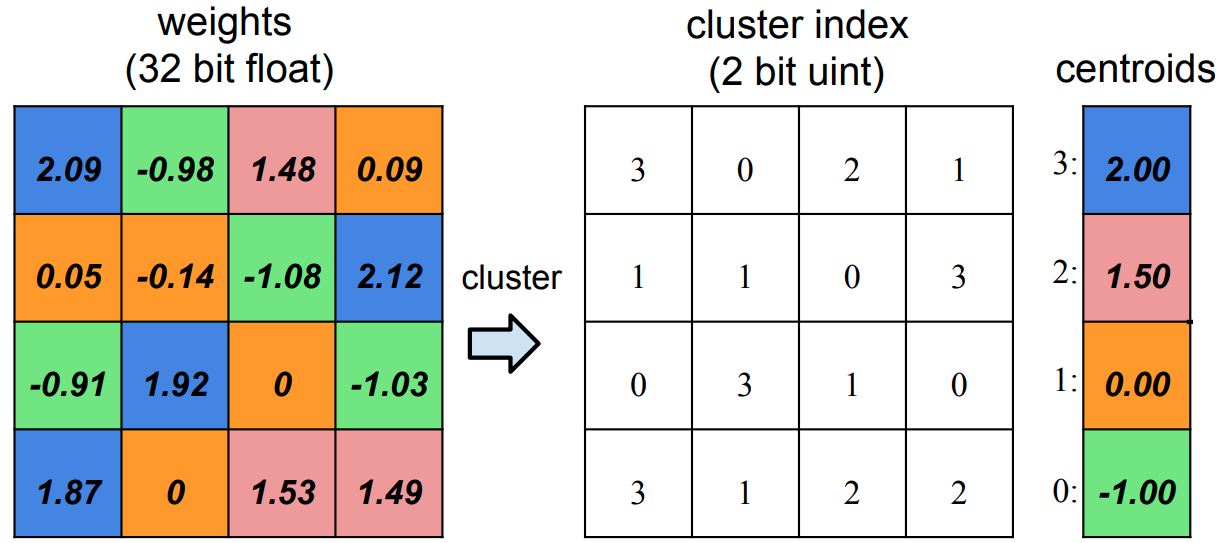


$n$-bit K-means quantization은 시냅스를 $2^n$개의 클러스터로 나누며, 동일한 클러스터에 속하는 시냅스는 동일한 가중치 값을 공유합니다.

따라서 K-means quantization은 다음을 포함하는 코드북을 생성합니다:

* centroids: $2^n$개의 FP32 클러스터들의 centroid.
* labels: 원래 FP32 가중치 텐서와 동일한 수의 요소를 가진 $n$-bit 정수 텐서. 각 정수는 해당하는 클러스터를 나타냅니다.

추론 중에, 추론용 코드북을 기반으로 fp32 텐서가 생성됩니다.

> ***quantized_weight* = *codebook.centroids*\[*codebook.labels*\].view_as(weight)**

In [39]:
from collections import namedtuple

Codebook = namedtuple('Codebook', ['centroids', 'labels'])

# [실습 4] K-means quantization 구현

다음 K-means quantization 함수를 완성해 주세요.

In [40]:
# fast-pytorch-kmeans를 우선 사용합니다. Windows에서 설치할 수 없다면
# 동일한 fit_predict() / centroids 인터페이스의 sklearn 기반 1-D 대체 구현을 사용합니다.
try:
    from fast_pytorch_kmeans import KMeans
    print('KMeans backend: fast-pytorch-kmeans')
except (ImportError, OSError) as exc:
    from sklearn.cluster import MiniBatchKMeans
    print(f'KMeans backend: sklearn MiniBatchKMeans (fallback: {exc})')

    class KMeans:
        def __init__(self, n_clusters, mode='euclidean', verbose=0):
            if mode != 'euclidean':
                raise ValueError('Fallback KMeans only supports euclidean distance')
            self.n_clusters = n_clusters
            self.centroids = None

        def fit_predict(self, x):
            if x.ndim != 2 or x.shape[1] != 1:
                raise ValueError('Fallback KMeans expects an [N, 1] input')
            x_cpu = x.detach().float().cpu().numpy()
            from numpy.random import default_rng
            n = len(x_cpu)
            rng = default_rng(0)
            subset = x_cpu[rng.choice(n, size=min(n, 100000), replace=False)] if n > 100000 else x_cpu
            estimator = MiniBatchKMeans(n_clusters=self.n_clusters, random_state=0,
                                        n_init=3, batch_size=4096, max_iter=60)
            estimator.fit(subset)
            # 메모리 사용량을 제한하기 위해 chunk 단위로 모든 라벨을 계산합니다.
            labels = []
            for start in range(0, n, 65536):
                labels.append(torch.from_numpy(estimator.predict(x_cpu[start:start + 65536])).long())
            self.centroids = torch.from_numpy(estimator.cluster_centers_).to(x.device, x.dtype)
            return torch.cat(labels).to(x.device)

dummy_tensor = torch.randn((20, 1))
kmeans = KMeans(n_clusters=4, mode='euclidean', verbose=0)
labels = kmeans.fit_predict(dummy_tensor)
centroids = kmeans.centroids

print('### Original Tensor ###')
print(dummy_tensor.view(-1))
print('### KMeans Labels ###')
print(labels)
print('### KMeans Centroids ###')
print(centroids.view(-1))


KMeans backend: fast-pytorch-kmeans
### Original Tensor ###
tensor([-0.3557, -0.3498, -2.2430,  0.0833,  0.6484,  0.0167, -2.3203,  0.3259,
        -0.0443,  1.4826, -2.8309, -1.1857, -1.2938,  1.7217, -0.7458, -0.9387,
         1.4443,  0.0091,  0.4580, -0.5566])
### KMeans Labels ###
tensor([2, 2, 0, 1, 1, 1, 0, 1, 1, 3, 0, 2, 2, 3, 2, 2, 3, 1, 1, 2])
### KMeans Centroids ###
tensor([-2.4648,  0.2139, -0.7752,  1.5495])


In [41]:
def k_means_quantize(fp32_tensor: torch.Tensor, bitwidth=4, codebook=None):
    """
    quantize tensor using k-means clustering
    :param fp32_tensor:
    :param bitwidth: [int] quantization bit width, default=4
    :param codebook: [Codebook] (the cluster centroids, the cluster label tensor)
    :return:
        [Codebook = (centroids, labels)]
            centroids: [torch.(cuda.)FloatTensor] the cluster centroids
            labels: [torch.(cuda.)LongTensor] cluster label tensor
    """
    if codebook is None:
        ############### YOUR CODE STARTS HERE ###############
        # bitwidth에 따라 클러스터 수를 설정하세요.
        n_clusters = 2**bitwidth
        ############### YOUR CODE ENDS HERE #################
        # k-means를 사용하여 quantization centroid를 얻습니다.
        kmeans = KMeans(n_clusters=n_clusters, mode='euclidean', verbose=0)
        labels = kmeans.fit_predict(fp32_tensor.view(-1, 1)).to(torch.long)
        centroids = kmeans.centroids.to(torch.float).view(-1)
        codebook = Codebook(centroids, labels)
    ############### YOUR CODE STARTS HERE ###############
    # 추론에서 사용할 quantized tensor를 구하기 위해 코드북을 디코딩하세요.
    quantized_tensor = codebook.centroids[codebook.labels]
    ############### YOUR CODE ENDS HERE #################
    fp32_tensor.set_(quantized_tensor.view_as(fp32_tensor))
    return codebook

tensor([2.2000, 3.3000, 4.4000])

Define misc funcions for verification.

In [42]:
def test_k_means_quantize(
    test_tensor=torch.tensor([
        [-0.3747,  0.0874,  0.3200, -0.4868,  0.4404],
        [-0.0402,  0.2322, -0.2024, -0.4986,  0.1814],
        [ 0.3102, -0.3942, -0.2030,  0.0883, -0.4741],
        [-0.1592, -0.0777, -0.3946, -0.2128,  0.2675],
        [ 0.0611, -0.1933, -0.4350,  0.2928, -0.1087]]),
    bitwidth=2):
    def plot_matrix(tensor, ax, title, cmap=ListedColormap(['white'])):
        ax.imshow(tensor.cpu().numpy(), vmin=-0.5, vmax=0.5, cmap=cmap)
        ax.set_title(title)
        ax.set_yticklabels([])
        ax.set_xticklabels([])
        for i in range(tensor.shape[1]):
            for j in range(tensor.shape[0]):
                text = ax.text(j, i, f'{tensor[i, j].item():.2f}',
                                ha="center", va="center", color="k")

    fig, axes = plt.subplots(1,2, figsize=(8, 12))
    ax_left, ax_right = axes.ravel()

    print(test_tensor)
    plot_matrix(test_tensor, ax_left, 'original tensor')

    num_unique_values_before_quantization = test_tensor.unique().numel()
    k_means_quantize(test_tensor, bitwidth=bitwidth)
    num_unique_values_after_quantization = test_tensor.unique().numel()
    print('* Test k_means_quantize()')
    print(f'    target bitwidth: {bitwidth} bits')
    print(f'        num unique values before k-means quantization: {num_unique_values_before_quantization}')
    print(f'        num unique values after  k-means quantization: {num_unique_values_after_quantization}')
    assert num_unique_values_after_quantization == min((1 << bitwidth), num_unique_values_before_quantization)
    print('* Test passed.')

    plot_matrix(test_tensor, ax_right, f'{bitwidth}-bit k-means quantized tensor', cmap='tab20c')
    fig.tight_layout()
    plt.show()

정의된 K-means quantization 함수의 기능을 확인하기 위해 더미 텐서에 위의 함수를 적용해 보겠습니다.

코드는 2-bit K-means quantization을 수행하고 quantization이전과 이후의 tensor를 보여줍니다. 각 클러스터는 고유한 색상으로 표현되며, quantized tensor에는 4개의 서로 다른 색상이 표시됩니다.

정확한 함수를 작성했다면 "Test passed." 라는 문장이 출력됩니다.

tensor([[-0.3747,  0.0874,  0.3200, -0.4868,  0.4404],
        [-0.0402,  0.2322, -0.2024, -0.4986,  0.1814],
        [ 0.3102, -0.3942, -0.2030,  0.0883, -0.4741],
        [-0.1592, -0.0777, -0.3946, -0.2128,  0.2675],
        [ 0.0611, -0.1933, -0.4350,  0.2928, -0.1087]])
* Test k_means_quantize()
    target bitwidth: 2 bits
        num unique values before k-means quantization: 25
        num unique values after  k-means quantization: 4
* Test passed.


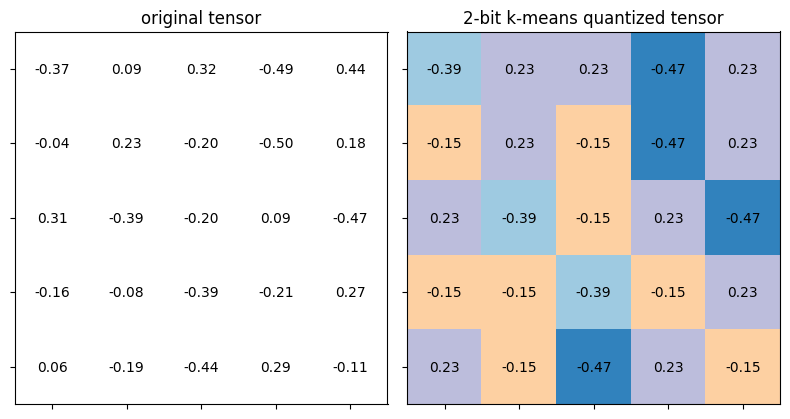

In [43]:
test_k_means_quantize()

## 전체 모델에 대한 K-means quantization

이전 실습에서 했던 것처럼, 이제 K-means quantization 함수를 전체 모델을 양자화하기 위한 클래스로 작성합니다. KMeansQuantizer 클래스에서는 코드북(즉, centroids와 labels)을 기록하여 모델 가중치가 변경될 때마다 코드북을 적용하거나 업데이트할 수 있도록 해야 합니다.

In [44]:
from torch.nn import parameter
class KMeansQuantizer:
    def __init__(self, model : nn.Module, bitwidth=4):
        self.codebook = KMeansQuantizer.quantize(model, bitwidth)

    @torch.no_grad()
    def apply(self, model, update_centroids):
        for name, param in model.named_parameters():
            if name in self.codebook:
                if update_centroids:
                    update_codebook(param, codebook=self.codebook[name])
                self.codebook[name] = k_means_quantize(
                    param, codebook=self.codebook[name])

    @staticmethod
    @torch.no_grad()
    def quantize(model: nn.Module, bitwidth=4):
        codebook = dict()
        if isinstance(bitwidth, dict):
            for name, param in model.named_parameters():
                if name in bitwidth:
                    codebook[name] = k_means_quantize(param, bitwidth=bitwidth[name])
        else:
            for name, param in model.named_parameters():
                if param.dim() > 1:
                    codebook[name] = k_means_quantize(param, bitwidth=bitwidth)
        return codebook

이제 K-means quantization을 사용하여 모델을 8비트, 4비트 및 2비트로 quantization하겠습니다.

*코드북의 저장 공간은 모델 크기를 계산할 때 무시됩니다.*

In [45]:
fp32_model_size = get_model_size(model)
print(f"    fp32 model의 크기={fp32_model_size/MiB:.2f} MiB")
quantizers = dict()
for bitwidth in [8,4,2]:
    recover_model()
    print(f'모델을 {bitwidth} bit로 quantization 합니다.')
    quantizer = KMeansQuantizer(model, bitwidth)
    quantized_model_size = get_model_size(model, bitwidth)
    print(f"    {bitwidth}-bit k-means quantized model의 크기 : {quantized_model_size/MiB:.2f} MiB")
    quantized_model_accuracy = evaluate(model, dataloader['test'])
    print(f"    {bitwidth}-bit k-means quantized model의 정확도 : {quantized_model_accuracy:.2f}%")
    quantizers[bitwidth] = quantizer

    fp32 model의 크기=35.20 MiB
모델을 8 bit로 quantization 합니다.
    8-bit k-means quantized model의 크기 : 8.80 MiB


eval:   0%|          | 0/1 [00:00<?, ?it/s]

    8-bit k-means quantized model의 정확도 : 93.00%
모델을 4 bit로 quantization 합니다.
    4-bit k-means quantized model의 크기 : 4.40 MiB


eval:   0%|          | 0/1 [00:00<?, ?it/s]

    4-bit k-means quantized model의 정확도 : 75.00%
모델을 2 bit로 quantization 합니다.
    2-bit k-means quantized model의 크기 : 2.20 MiB


eval:   0%|          | 0/1 [00:00<?, ?it/s]

    2-bit k-means quantized model의 정확도 : 10.00%


## Quantization-aware training(QAT)

마지막 셀의 결과에서 볼 수 있듯이, 모델을 낮은 비트로 quantization할 때 정확도가 크게 떨어집니다. 따라서 정확도를 회복하기 위해 Quantization-aware training(QAT)을 수행해야 합니다.

K-means quantization-aware training 동안, centroid도 업데이트됩니다. 이는 [Deep Compression: Compressing Deep Neural Networks With Pruning, Trained Quantization
And Huffman Coding](https://arxiv.org/pdf/1510.00149.pdf)에서 제안된 방법입니다.

centroid의 gradient는 다음과 같이 계산할 수 있습니다.

> $\frac{\partial \mathcal{L}}{\partial C_k} = \sum_{j} \frac{\partial \mathcal{L} }{\partial W_{j}} \frac{\partial W_{j} }{\partial C_k} = \sum_{j} \frac{\partial \mathcal{L} }{\partial W_{j}} \mathbf{1}(I_{j}=k)$

여기서 $\mathcal{L}$ 는 loss이며, $C_k$ 는 *k*번째 centroid, $I_{j}$는 가중치 $W_{j}$에 대한 label입니다.

$\mathbf{1}()$ 는 지시함수로, 만약 $I_{j}=k\; 이라면
\;\mathbf{1}(I_{j}=k)$ 는$\;1, 아니면\;0$이 됩니다.

&nbsp;

이번 실습에서는 단순성을 위해 다음과 같이 최신 가중치에 따라 centroid를 직접 업데이트하겠습니다:

> $C_k = \frac{\sum_{j}W_{j}\mathbf{1}(I_{j}=k)}{\sum_{j}\mathbf{1}(I_{j}=k)}$

# [실습 5] Quantization Aware Training 구현

다음 코드북 업데이트 함수를 완성해 주세요.

**Hint**:

위의 centorid 업데이트 방정식은 동일한 클러스터 내에 있는 가중치들의 평균을 사용하여 centorid 값을 새로 업데이트하는 것입니다.

In [46]:
def update_codebook(fp32_tensor: torch.Tensor, codebook: Codebook):
    """
    update the centroids in the codebook using updated fp32_tensor
    :param fp32_tensor: [torch.(cuda.)Tensor]
    :param codebook: [Codebook] (the cluster centroids, the cluster label tensor)
    """
    n_clusters = codebook.centroids.numel()
    fp32_tensor = fp32_tensor.view(-1)
    for k in range(n_clusters):
    ############### YOUR CODE STARTS HERE ###############
    # hint : torch.mean() 함수를 이용하여 평균을 구할 수 있습니다.
        codebook.centroids[k] = torch.mean(fp32_tensor[codebook.labels==k])
    ############### YOUR CODE ENDS HERE #################

이제 다음 코드 셀을 실행하여 8,4,2-bit K-means quantized 모델을 fine-tune하여 정확도를 회복하겠습니다.

정확도 감소가 1%p 미만이 되면 fine-tuning을 중단합니다.

In [47]:

def train(
  model: nn.Module,
  dataloader: DataLoader,
  criterion: nn.Module,
  optimizer: Optimizer,
  scheduler: LambdaLR,
  callbacks = None
) -> None:
  model.train()

  for inputs, targets in tqdm(dataloader, desc='train', leave=False):
    # Use CPU or CUDA depending on model placement.
    current_device = model_device(model)
    inputs = inputs.to(current_device)
    targets = targets.to(current_device)

    # Reset the gradients (from the last iteration)
    optimizer.zero_grad()

    # Forward inference
    outputs = model(inputs)
    loss = criterion(outputs, targets)

    # Backward propagation
    loss.backward()

    # Update optimizer and LR scheduler
    optimizer.step()
    scheduler.step()

    if callbacks is not None:
        for callback in callbacks:
            callback()

@torch.inference_mode()
def evaluate(
  model: nn.Module,
  dataloader: DataLoader,
  extra_preprocess = None
) -> float:
  model.eval()

  num_samples = 0
  num_correct = 0

  for inputs, targets in tqdm(dataloader, desc="eval", leave=False):
    # Use CPU or CUDA depending on model placement.
    current_device = model_device(model)
    inputs = inputs.to(current_device)
    if extra_preprocess is not None:
        for preprocess in extra_preprocess:
            inputs = preprocess(inputs)

    targets = targets.to(current_device)

    # Inference
    outputs = model(inputs)

    # Convert logits to class indices
    outputs = outputs.argmax(dim=1)

    # Update metrics
    num_samples += targets.size(0)
    num_correct += (outputs == targets).sum()

  return (num_correct / num_samples * 100).item()

# 앞에서 다운로드한 동일한 VGG 체크포인트를 재사용 (torch.hub 추가 설치 불필요).
model = model.to(DEVICE)
recover_model()

accuracy_drop_threshold = 1
quantizers_before_finetune = copy.deepcopy(quantizers)
quantizers_after_finetune = quantizers

for bitwidth in [8,4,2]:
    recover_model()
    quantizer = KMeansQuantizer(model, bitwidth)
    print(f'모델을 {bitwidth} bit로 quantization 합니다.')
    quantizer.apply(model, update_centroids=False)
    quantized_model_size = get_model_size(model, bitwidth)
    print(f"    {bitwidth}-bit k-means quantized model의 크기 : {quantized_model_size/MiB:.2f} MiB")
    quantized_model_accuracy = evaluate(model, dataloader['test'])
    print(f"    {bitwidth}-bit k-means quantized model의 정확도 : {quantized_model_accuracy:.2f}% before QAT ")
    accuracy_drop = fp32_model_accuracy - quantized_model_accuracy
    if accuracy_drop > accuracy_drop_threshold:
        print(f"        정확도 감소가 {accuracy_drop:.2f}%p이므로 Quantization-aware training을 진행합니다.")
        num_finetune_epochs = 5
        optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, num_finetune_epochs)
        criterion = nn.CrossEntropyLoss()
        best_accuracy = 0
        epoch = num_finetune_epochs
        while accuracy_drop > accuracy_drop_threshold and epoch > 0:
            train(model, dataloader['train'], criterion, optimizer, scheduler,
                  callbacks=[lambda: quantizer.apply(model, update_centroids=True)])
            model_accuracy = evaluate(model, dataloader['test'])
            is_best = model_accuracy > best_accuracy
            best_accuracy = max(model_accuracy, best_accuracy)
            print(f'    Epoch {num_finetune_epochs-epoch} Accuracy {model_accuracy:.2f}% / Best Accuracy: {best_accuracy:.2f}%')
            accuracy_drop = fp32_model_accuracy - best_accuracy
            epoch -= 1
        print(f"        정확도 감소가 {accuracy_drop:.2f}%p이므로 Quantization-aware training을 종료합니다.")
    else:
        print(f"        정확도 감소가 {accuracy_drop:.2f}%p이므로 Quantization-aware training을 종료합니다.")

모델을 8 bit로 quantization 합니다.
    8-bit k-means quantized model의 크기 : 8.80 MiB


eval:   0%|          | 0/1 [00:00<?, ?it/s]

    8-bit k-means quantized model의 정확도 : 92.00% before QAT 
        정확도 감소가 1.00%p이므로 Quantization-aware training을 진행합니다.


train:   0%|          | 0/98 [00:00<?, ?it/s]

eval:   0%|          | 0/1 [00:00<?, ?it/s]

...

eval:   0%|          | 0/1 [00:00<?, ?it/s]

    Epoch 0 Accuracy 91.00% / Best Accuracy: 91.00%


train:   0%|          | 0/98 [00:00<?, ?it/s]

eval:   0%|          | 0/1 [00:00<?, ?it/s]

    Epoch 1 Accuracy 93.00% / Best Accuracy: 93.00%
        정확도 감소가 0.00%p이므로 Quantization-aware training을 종료합니다.


# 2.3. Llama.cpp 실습

이제 llama.cpp 실습을 진행해 보도록 하겠습니다.

먼저 llama.cpp의 build binary와 사용할 모델을 다운받도록 하겠습니다.

모델은 Qwen3.5-4B를 사용하도록 하겠습니다.

In [48]:
import gc
import torch

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [49]:
# llama.cpp: 공식 GitHub Release b10711의 Windows x64 바이너리를 직접 다운로드합니다.
# 검증한 배포 링크: https://github.com/ggml-org/llama.cpp/releases/tag/b10711
# Windows CPU: llama-b10711-bin-win-cpu-x64.zip
# Windows CUDA12.4: llama-b10711-bin-win-cuda-12.4-x64.zip + cudart-llama-bin-win-cuda-12.4-x64.zip
# Windows CUDA13.3: llama-b10711-bin-win-cuda-13.3-x64.zip + cudart-llama-bin-win-cuda-13.3-x64.zip
# Linux x64 CPU: llama-b10711-bin-ubuntu-x64.tar.gz
# CUDA 런타임 바이너리와 DLL 파일은 반드시 *같은 릴리스*의 것을 사용합니다.
from pathlib import Path
from urllib.request import Request, urlopen
import os
import platform
import shutil
import subprocess
import tarfile
import zipfile
import hashlib

LLAMA_RELEASE_TAG = 'b10711'  # Linux 정답본에서 검증된 정확히 같은 커밋 (9723942adc) 사용
# 'auto', 'cpu', 'cuda12', 'cuda13' 중 선택 (CUDA 모드는 Windows x64 + NVIDIA GPU)
LLAMA_BACKEND = 'auto'


def pick_llama_backend(preferred):
    if preferred not in ('auto', 'cpu', 'cuda12', 'cuda13'):
        raise ValueError(f'Unknown backend: {preferred}')
    if preferred != 'auto':
        return preferred
    if platform.system() == 'Windows' and torch.cuda.is_available():
        # Blackwell(GeForce RTX 50 등)은 CUDA12.4 빌드와 호환되지 않을 수 있습니다.
        # 이 경우 CUDA13.3을 선택합니다. NVIDIA 드라이버가 CUDA13.3을 지원해야 합니다.
        try:
            compute_major, _ = torch.cuda.get_device_capability(0)
        except Exception:
            compute_major = 0
        return 'cuda13' if compute_major >= 10 else 'cuda12'
    return 'cpu'


def llama_release_filenames(system, arch, backend, tag):
    arch = arch.lower()
    if arch not in ('amd64', 'x86_64'):
        raise RuntimeError(f'현재 실습 바이너리는 x64만 지원합니다: {system}/{arch}')
    if system == 'Windows':
        if backend == 'cpu':
            return [f'llama-{tag}-bin-win-cpu-x64.zip']
        if backend == 'cuda12':
            return [f'llama-{tag}-bin-win-cuda-12.4-x64.zip',
                    'cudart-llama-bin-win-cuda-12.4-x64.zip']
        if backend == 'cuda13':
            return [f'llama-{tag}-bin-win-cuda-13.3-x64.zip',
                    'cudart-llama-bin-win-cuda-13.3-x64.zip']
    elif system == 'Linux' and backend == 'cpu':
        return [f'llama-{tag}-bin-ubuntu-x64.tar.gz']
    raise RuntimeError(f'미지원 조합: {system}/{arch}/{backend}. Windows CUDA 또는 Linux CPU를 선택하세요.')


LLAMA_BACKEND = pick_llama_backend(LLAMA_BACKEND)
LLAMA_ASSETS = llama_release_filenames(platform.system(), platform.machine(),
                                       LLAMA_BACKEND, LLAMA_RELEASE_TAG)
LLAMA_RELEASE_URL = f'https://github.com/ggml-org/llama.cpp/releases/download/{LLAMA_RELEASE_TAG}'
LLAMA_BIN_DIR = LAB_DIR / 'llama-bin' / LLAMA_RELEASE_TAG / LLAMA_BACKEND
LLAMA_BIN_DIR.mkdir(parents=True, exist_ok=True)
# 공식 GitHub build attestation: https://github.com/ggml-org/llama.cpp/attestations/44046740
# Linux 원본: build 10711, commit 9723942ad
LLAMA_ASSET_SHA256 = {'llama-b10711-bin-win-cpu-x64.zip': '0667f1c640038226ea28da572d415710fef63555c8afeaf4ef7e542f6240e100', 'llama-b10711-bin-win-cuda-12.4-x64.zip': '519dd0dd676e2a1e5b83e8780acf92f3e531690c0564f871fd4f62bc65e7d8d6', 'llama-b10711-bin-win-cuda-13.3-x64.zip': '079bdc923238b0cf2c8af1a6c68dd2f21693d3d356036db3502f9b90e1e0decb', 'cudart-llama-bin-win-cuda-12.4-x64.zip': '8c79a9b226de4b3cacfd1f83d24f962d0773be79f1e7b75c6af4ded7e32ae1d6', 'cudart-llama-bin-win-cuda-13.3-x64.zip': '1462a050eb4c684921ba51dcc4cc488a036674c3e73e9945ee705b854808d03e'}

REQUIRED_TOOLS = ('llama-quantize', 'llama-cli', 'llama-perplexity')


def llama_exe(tool):
    if tool not in REQUIRED_TOOLS:
        raise ValueError(f'Unexpected llama.cpp tool: {tool}')
    filename = tool + ('.exe' if platform.system() == 'Windows' else '')
    matches = sorted(LLAMA_BIN_DIR.rglob(filename))
    if not matches:
        raise FileNotFoundError(f'{filename} not found under {LLAMA_BIN_DIR}')
    return matches[0]


def _llama_install_complete():
    if not all(list(LLAMA_BIN_DIR.rglob(tool + ('.exe' if platform.system() == 'Windows' else '')))
               for tool in REQUIRED_TOOLS):
        return False
    if platform.system() == 'Windows' and LLAMA_BACKEND.startswith('cuda'):
        # Windows NVIDIA 배포는 실행 파일 ZIP과 cudart ZIP 두 개를 설치해야 합니다.
        # CUDA 패키지의 cuBLAS DLL이 빠진 상태는 완료로 간주하지 않습니다.
        return any('cublas64_' in p.name.lower() for p in LLAMA_BIN_DIR.rglob('*.dll'))
    return True


def _extract_official_archive(archive_path):
    # ZIP path traversal 방어
    if archive_path.name.endswith('.zip'):
        with zipfile.ZipFile(archive_path) as zf:
            base = LLAMA_BIN_DIR.resolve()
            for info in zf.infolist():
                if not (base / info.filename).resolve().is_relative_to(base):
                    raise ValueError(f'Unexpected ZIP entry: {info.filename}')
            zf.extractall(base)
    elif archive_path.name.endswith('.tar.gz'):
        with tarfile.open(archive_path, 'r:gz') as tf:
            tf.extractall(LLAMA_BIN_DIR, filter='data')
    else:
        raise ValueError(f'Unsupported archive: {archive_path.name}')


def _download_official_asset(filename):
    url = f'{LLAMA_RELEASE_URL}/{filename}'
    local_zip = LLAMA_BIN_DIR / filename
    tmp_file = local_zip.with_name(local_zip.name + '.part')
    print('Official Release:', url)
    try:
        req = Request(url, headers={'User-Agent': 'AVD-Quantization-Lab/1.0'})
        sha256 = hashlib.sha256()
        with urlopen(req, timeout=120) as response, tmp_file.open('wb') as dst:
            while True:
                part = response.read(1024 * 1024)
                if not part:
                    break
                dst.write(part)
                sha256.update(part)
        expected = LLAMA_ASSET_SHA256.get(filename)
        if expected and sha256.hexdigest() != expected:
            raise RuntimeError(
                f'공식 릴리스와 SHA256 불일치: {filename}\n'
                f'expected={expected}\nactual={sha256.hexdigest()}'
            )
        if expected:
            print('SHA256: GitHub attestation과 일치')
        tmp_file.replace(local_zip)
        _extract_official_archive(local_zip)
    except Exception as exc:
        raise RuntimeError(
            f'Failed to download/extract: {url}\n'
            '회사/학교 네트워크에서 GitHub 다운로드가 차단되면 이 URL을 브라우저로 '
            f'다운로드해 {LLAMA_BIN_DIR}에 압축 해제하세요.'
        ) from exc
    finally:
        tmp_file.unlink(missing_ok=True)
        local_zip.unlink(missing_ok=True)


def install_llama_cpp():
    if _llama_install_complete():
        print(f'Existing llama.cpp binary: {LLAMA_BIN_DIR}')
        return
    print(f'Installing official llama.cpp {LLAMA_RELEASE_TAG} for {LLAMA_BACKEND}')
    for filename in LLAMA_ASSETS:
        _download_official_asset(filename)
    if not _llama_install_complete():
        raise RuntimeError(f'다운로드 후 실행 파일/DLL을 찾지 못했습니다: {LLAMA_BIN_DIR}')
    if platform.system() != 'Windows':
        for tool in REQUIRED_TOOLS:
            exe = llama_exe(tool)
            exe.chmod(exe.stat().st_mode | 0o111)
    print(f'Installed: {LLAMA_BIN_DIR}')


# Windows llama.cpp b10711은 비ASCII 경로(예: '실습')의 GGUF를 열지 못할 수 있습니다.
# 모델은 원래 경로에 그대로 보관하면서 실행 시에만 ASCII 경로를 이용합니다.
# 같은 NTFS 볼륨에서는 hard link를 사용해 대용량 GGUF를 복사하지 않습니다.
# hard link가 불가능하면 임시 폴더에 한 번만 복사해 재사용합니다.
import re
import tempfile


def _llama_ascii_cache_dir():
    if platform.system() != 'Windows':
        return None
    candidates = [
        os.environ.get('TEMP'),
        os.environ.get('TMP'),
        tempfile.gettempdir(),
        str(Path(os.environ.get('PUBLIC', 'C:/Users/Public'))),
    ]
    for parent in candidates:
        if not parent:
            continue
        folder = Path(parent) / 'AVD_llama_ascii_paths'
        if not str(folder).isascii():
            continue
        try:
            folder.mkdir(parents=True, exist_ok=True)
            return folder
        except OSError:
            continue
    raise RuntimeError(
        'Windows ASCII 임시 폴더를 만들지 못했습니다. '
        'TEMP 환경 변수를 영문 경로로 설정하거나, 실습 폴더를 영문 경로로 옮기세요.'
    )


LLAMA_ASCII_CACHE = _llama_ascii_cache_dir()


def _ascii_cache_name(prefix, original):
    src = Path(original).absolute()
    digest = hashlib.sha256(str(src).encode('utf-8')).hexdigest()[:16]
    # 임시 파일명과 경로 전체에 ASCII 문자만 사용
    safe_name = re.sub(r'[^a-zA-Z0-9._-]', '_', src.name)[:75]
    return LLAMA_ASCII_CACHE / f'{prefix}-{digest}-{safe_name}'


def _llama_safe_input(path):
    """Windows에서 Unicode 파일명을 llama.cpp에 ASCII 경로로 노출합니다."""
    path = Path(path)
    if platform.system() != 'Windows' or str(path).isascii():
        return path
    if not path.is_file():
        raise FileNotFoundError(f'llama.cpp 입력 파일이 없습니다: {path}')
    alias = _ascii_cache_name('input', path)
    src_info = path.stat()
    if alias.exists():
        try:
            if alias.samefile(path):
                return alias
        except OSError:
            pass
        dst_info = alias.stat()
        if (dst_info.st_size == src_info.st_size and
                dst_info.st_mtime_ns == src_info.st_mtime_ns):
            # 이전 실행에서 생성된 단순 복사본 재사용
            return alias
        alias.unlink()
    try:
        os.link(path, alias)  # NTFS 동일 드라이브: 데이터 복사 없이 생성
        print(f'[Windows 경로 우회] GGUF hard link 생성: {alias}')
    except OSError:
        free = shutil.disk_usage(LLAMA_ASCII_CACHE).free
        if free < src_info.st_size + 128 * 1024**2:
            raise RuntimeError(
                f'ASCII 임시 폴더의 여유 공간이 부족합니다. 필요한 크기: '
                f'{src_info.st_size / 1024**3:.2f} GiB. '
                '실습 폴더 자체를 영문 경로로 옮기면 추가 복사를 피할 수 있습니다.'
            )
        print(f'[Windows 경로 우회] hard link 불가 → ASCII 임시 폴더로 1회 복사: {alias}')
        shutil.copy2(path, alias)
    return alias


def _llama_safe_output(path):
    """새 GGUF의 Windows 비ASCII 출력 경로를 임시 ASCII 경로로 변경합니다."""
    path = Path(path)
    if platform.system() != 'Windows' or str(path).isascii():
        return path
    temporary = _ascii_cache_name('output', path)
    # 이전에 실패한 양자화 결과가 재사용되지 않도록 제거
    temporary.unlink(missing_ok=True)
    return temporary


def _llama_restore_output(temporary, original):
    """양자화 결과는 원래 models 폴더(한글 경로 포함)에 저장합니다."""
    temporary, original = Path(temporary), Path(original)
    if temporary == original:
        return
    original.parent.mkdir(parents=True, exist_ok=True)
    try:
        os.replace(temporary, original)  # 동일 드라이브: 추가 파일 복사 없음
    except OSError:
        # 다른 볼륨이라면 shutil.move로 복사 후 삭제
        # 기존 출력이 있다면 덮어쓰는 동작을 명시적으로 수행합니다.
        alternate = original.with_name(original.name + '.avd-in-progress')
        try:
            shutil.copy2(temporary, alternate)
            os.replace(alternate, original)
            temporary.unlink(missing_ok=True)
        finally:
            alternate.unlink(missing_ok=True)


def _llama_argument(arg):
    # -m 모델, -f 평가 데이터 등 Path 인자를 자동으로 처리합니다.
    # 양자화 출력은 _llama_safe_output()으로 별도 처리합니다.
    if platform.system() != 'Windows':
        return str(arg)
    if isinstance(arg, Path):
        if not str(arg).isascii() and arg.is_file():
            return str(_llama_safe_input(arg))
    elif isinstance(arg, str) and not arg.isascii() and ('\\' in arg or '/' in arg):
        possible = Path(arg)
        if possible.is_file():
            return str(_llama_safe_input(possible))
    return str(arg)


if LLAMA_ASCII_CACHE is not None:
    print('llama.cpp Windows Unicode 경로 보호 활성화:', LLAMA_ASCII_CACHE)



def run_llama(tool, *args, capture_output=False, check=True):
    """llama.cpp stdout/stderr를 Jupyter 셀에 실시간 출력합니다.

    capture_output=True: 실시간으로 표시하면서 CompletedProcess.stdout에도 전체 보관
    capture_output=False: 실시간으로 표시하고 에러 발생 시 마지막 로그를 예외에 포함
    Windows/Unicode 경로 및 설치 바이너리 선택은 이전 기능을 유지합니다.
    """
    import codecs
    import shlex
    import sys
    from collections import deque

    exe = llama_exe(tool)
    env = os.environ.copy()
    if platform.system() == 'Windows':
        dll_dirs = {str(exe.parent)} | {str(p.parent) for p in LLAMA_BIN_DIR.rglob('*.dll')}
        env['PATH'] = os.pathsep.join(sorted(dll_dirs)) + os.pathsep + env.get('PATH', '')
    else:
        lib_dirs = {str(exe.parent)} | {str(p.parent) for p in LLAMA_BIN_DIR.rglob('*.so*')}
        env['LD_LIBRARY_PATH'] = os.pathsep.join(sorted(lib_dirs)) + os.pathsep + env.get('LD_LIBRARY_PATH', '')

    command = [str(exe)] + [_llama_argument(x) for x in args]
    printable = (subprocess.list2cmdline(command) if platform.system() == 'Windows'
                 else shlex.join(command))
    print('>', printable, flush=True)
    print(f'[llama.cpp] Running {tool} | release={LLAMA_RELEASE_TAG} | backend={LLAMA_BACKEND}',
          flush=True)

    # Jupyter에서는 자식 프로세스 stdout/stderr를 그대로 상속하면 노트북이 아니라
    # Jupyter 서버 터미널로 출력될 수 있습니다. PIPE로 모아 Python stdout으로 중계합니다.
    try:
        proc = subprocess.Popen(
            command, cwd=exe.parent, env=env,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            bufsize=0,  # Windows pipe에서 readline()의 개행 대기로 인한 지연 방지
        )
    except OSError as exc:
        raise RuntimeError('llama.cpp 실행 파일/DLL 시작 실패. CUDA DLL과 NVIDIA 드라이버를 '
                           '확인하거나 LLAMA_BACKEND="cpu"를 사용하세요.') from exc

    decoder = codecs.getincrementaldecoder('utf-8')(errors='replace')
    captured = [] if capture_output else None
    recent = deque(maxlen=256)  # 실패 진단용 마지막 약 256 KiB

    def _emit(chunk):
        if not chunk:
            return
        # Python stdout은 ipykernel이 수집해 노트북 셀에 실시간 표시합니다.
        sys.stdout.write(chunk)
        sys.stdout.flush()
        recent.append(chunk)
        if captured is not None:
            captured.append(chunk)

    try:
        while True:
            raw = proc.stdout.read(1024)  # 비버퍼링: 개행이 없는 PPL 진행률도 전달
            if not raw:
                break
            _emit(decoder.decode(raw, final=False))
        _emit(decoder.decode(b'', final=True))
        returncode = proc.wait()
    except BaseException:
        # Notebook의 Interrupt Kernel로 종료할 때 자식 llama 프로세스를 남기지 않음
        if proc.poll() is None:
            proc.terminate()
            try:
                proc.wait(timeout=5)
            except subprocess.TimeoutExpired:
                proc.kill()
                proc.wait()
        raise
    finally:
        if proc.stdout is not None:
            proc.stdout.close()

    result = subprocess.CompletedProcess(
        command, returncode,
        stdout=''.join(captured) if captured is not None else None,
    )
    if check and returncode != 0:
        # 줄바꿈 없는 CR 진행률도 splitlines()로 분리해 보여줍니다.
        tail = '\n'.join(''.join(recent).splitlines()[-75:])
        raise RuntimeError(
            f'{tool} 실패(exit={returncode}, release={LLAMA_RELEASE_TAG}, '
            f'backend={LLAMA_BACKEND}).\n'
            f'원본 llama.cpp 오류 로그(마지막 75줄):\n{tail}\n'
            '실제 오류를 확인하세요. 양자화 타입 미지원으로 단정하지 않습니다.'
        )
    print(f'[llama.cpp] Finished {tool} (exit={returncode})', flush=True)
    return result


def quantize_gguf(output_filename, quant_type):
    """Linux --pure와 동일. Windows 비ASCII GGUF 경로는 ASCII hard link로 우회."""
    source = MODEL_DIR / 'Qwen3.5-4B.fp16.gguf'
    output = MODEL_DIR / output_filename
    if not source.is_file():
        raise FileNotFoundError(f'원본 FP16 GGUF 없음: {source}')
    with source.open('rb') as fp:
        if fp.read(4) != b'GGUF':
            raise ValueError(f'원본 파일이 GGUF가 아닙니다: {source}')

    # 원본 파일은 이동하지 않습니다. 한글 경로일 때에만 임시 ASCII 결과를 생성합니다.
    safe_output = _llama_safe_output(output)
    try:
        proc = run_llama('llama-quantize', '--pure', source, safe_output, quant_type,
                         capture_output=True)
        if not safe_output.is_file() or safe_output.stat().st_size <= 1024 * 1024:
            raise RuntimeError(f'명령어 종료는 성공이지만 GGUF가 생성되지 않았습니다: {safe_output}')
        with safe_output.open('rb') as fp:
            if fp.read(4) != b'GGUF':
                raise RuntimeError(f'양자화 결과의 GGUF 헤더가 올바르지 않습니다: {safe_output}')
        _llama_restore_output(safe_output, output)
    except Exception:
        # 실패한 결과만 정리합니다. 기존에 성공한 파일은 삭제하지 않습니다.
        if safe_output != output:
            safe_output.unlink(missing_ok=True)
        elif output.is_file() and output.stat().st_size < 1024 * 1024:
            output.unlink()
        raise

    logs = (proc.stdout or '').splitlines()
    for line in logs:
        if ('version:' in line or 'llama_quantize: quantizing' in line
                or 'quant size' in line or 'quantize time' in line or 'total time' in line):
            print(line)
    builds = re.findall(r'\bbuild\s+(\d+)', proc.stdout or '')
    if builds and any(int(b) != 10711 for b in builds):
        raise RuntimeError(f'예상과 다른 llama.cpp 빌드! 발견: {builds}, 기대: b10711')
    if not output.is_file() or output.stat().st_size <= 1024 * 1024:
        raise RuntimeError(f'양자화 결과 GGUF를 원래 모델 폴더에서 찾을 수 없습니다: {output}')
    with output.open('rb') as fp:
        if fp.read(4) != b'GGUF':
            raise RuntimeError(f'양자화 결과 GGUF 헤더가 올바르지 않습니다: {output}')
    print(f'[OK] {quant_type}: {output.name} ({output.stat().st_size / 1024**3:.2f} GiB)')
    return output

install_llama_cpp()
LLAMA_GPU_LAYERS = 99 if LLAMA_BACKEND.startswith('cuda') else 0
LLAMA_MAX_NEW_TOKENS = 1024 if LLAMA_GPU_LAYERS else 128
LLAMA_PPL_CHUNKS = 10 if LLAMA_GPU_LAYERS else 2
print(f'Backend: {LLAMA_BACKEND} | Release: {LLAMA_RELEASE_TAG} | GPU layers: {LLAMA_GPU_LAYERS}')


llama.cpp Windows Unicode 경로 보호 활성화: C:\Users\SWSUSE~1\AppData\Local\Temp\AVD_llama_ascii_paths
Installing official llama.cpp b10711 for cuda12
Official Release: https://github.com/ggml-org/llama.cpp/releases/download/b10711/llama-b10711-bin-win-cuda-12.4-x64.zip
SHA256: GitHub attestation과 일치
Official Release: https://github.com/ggml-org/llama.cpp/releases/download/b10711/cudart-llama-bin-win-cuda-12.4-x64.zip
SHA256: GitHub attestation과 일치
Installed: C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12
Backend: cuda12 | Release: b10711 | GPU layers: 99


In [50]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print('GGUF model directory:', MODEL_DIR)

GGUF model directory: C:\Users\swsuser-k51\Documents\Practice_materials\models


In [51]:
from huggingface_hub import hf_hub_download

f16_model = hf_hub_download(
    repo_id="AaryanK/Qwen3.5-4B-GGUF",
    filename="Qwen3.5-4B.fp16.gguf",
    local_dir=str(MODEL_DIR),
)

print(f16_model)

Qwen3.5-4B.fp16.gguf:   0%|          | 0.00/8.42G [00:00<?, ?B/s]

C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.fp16.gguf


이제 Windows의 NVIDIA GPU / CPU 상태와, 설치된 llama.cpp의 실행 파일을 확인해 보겠습니다.

Windows에서는 `.exe`와 `.dll`을 사용하고, Linux에서는 ELF 실행 파일과 `.so`를 사용합니다. 공통 함수 `run_llama()`가 운영체제에 맞는 실행 파일 및 라이브러리 경로를 처리합니다.

**실시간 로그 출력:** quantization, inference, perplexity 실행 중 C++ stdout/stderr를 아래 셀에 표시합니다. 로그가 길거나 진행률이 `\r`로 갱신되더라도 실행 상황을 확인할 수 있습니다.


In [52]:
# 장치 및 바이너리 상태 확인 (nvidia-smi/ldconfig/find 등 Linux 셸 명령 불필요)
print('OS:', platform.system(), platform.machine())
print('PyTorch CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    print('PyTorch CUDA runtime:', torch.version.cuda)
else:
    print('GPU가 없으면 llama.cpp CPU 바이너리로 실습을 진행합니다.')


OS: Windows AMD64
PyTorch CUDA available: True
GPU: Tesla T4
PyTorch CUDA runtime: 12.4


In [53]:
for tool in ('llama-quantize', 'llama-cli', 'llama-perplexity'):
    print(f'{tool}: {llama_exe(tool)}')
print(f'기대한 릴리스: {LLAMA_RELEASE_TAG} (Linux 원본 빌드와 동일)')
print('llama-quantize --help 요약:')
probe = run_llama('llama-quantize', '--help', capture_output=True, check=False)
help_text = probe.stdout or ''
for line in help_text.splitlines()[:30]:
    print('  ', line)
print('MXFP4_MOE 타입이 --help에 열거되는가:', 'MXFP4_MOE' in help_text)
# 양자화가 실패하면 이제 원본 C++ stderr/stdout 마지막 75줄이 RuntimeError에 표시됩니다.


llama-quantize: C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-quantize.exe
llama-cli: C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-cli.exe
llama-perplexity: C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-perplexity.exe
기대한 릴리스: b10711 (Linux 원본 빌드와 동일)
llama-quantize --help 요약:
> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-quantize.exe --help
[llama.cpp] Running llama-quantize | release=b10711 | backend=cuda12
usage: C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-quantize.exe [--help] [--allow-requantize] [--leave-output-tensor] [--pure] [--imatrix] [--include-weights]
       [--exclude-weights] [--output-tensor-type] [--token-embedding-type] [--tensor-type] [--tensor-type-file]
       [--prune-layers] [--keep-split] [--override-kv] [--dry-run] [--max-buffer-size]
       model-f32.gguf [model-quant.gguf] type [nthread

이제 다운로드한 FP16 Qwen3.5-4B GGUF를 양자화합니다. Linux 실습과 **동일한 build 10711** 및 `--pure` 옵션을 사용합니다.

- Q8_0, Q4_0, MXFP4_MOE, Q4_1, Q4_K를 차례로 생성합니다.
- `--pure`는 가능한 레이어에 동일한 양자화 형식을 적용하도록 지정합니다. 레이어 shape에 따라 예외적인 텐서는 원래 정밀도로 유지될 수 있습니다.
- 실패하면 이전과 달리 `Quantization unsupported/failed`로 일괄 처리하지 않고 **실제 llama.cpp 오류 로그를 표시하고 중단**합니다.
- IQ4_NL은 imatrix 생성 시간이 길어 미리 만든 GGUF를 다운로드합니다.


**Windows 한글 경로 자동 보호:** `실습`처럼 한글 폴더를 사용하더라도 모델 원본을 옮길 필요는 없습니다. 처음 실행할 때 같은 드라이브라면 NTFS hard link(추가 디스크 공간 거의 없음), 그 외에는 ASCII 임시 폴더에 한 번 복사하는 방식으로 `llama.cpp`가 모델을 열 수 있도록 합니다. 양자화 출력은 기존 `models/`에 저장하며, 이후 `llama-cli` 및 `llama-perplexity`도 자동 처리합니다.


In [54]:
# Linux 원본과 동일한 --pure Q8_0. 오류 발생 시 C++ 로그와 함께 즉시 중단합니다.
quantize_gguf('Qwen3.5-4B.Q8_0.gguf', 'Q8_0')


> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-quantize.exe --pure C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.fp16.gguf C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.Q8_0.gguf Q8_0
[llama.cpp] Running llama-quantize | release=b10711 | backend=cuda12
ggml_cuda_init: found 1 CUDA devices (Total VRAM: 16383 MiB):
  Device 0: Tesla T4, compute capability 7.5, VMM: yes, VRAM: 16383 MiB
load_backend: loaded CUDA backend from C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\ggml-cuda.dll
load_backend: loaded RPC backend from C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\ggml-rpc.dll
load_backend: loaded CPU backend from C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\ggml-cpu-haswell.dll
version: 0.3.0-dev (build 10711, commit 9723942ad)
built with Clang 20.1.8 for Windows x86_64
llama_quantize: quantizing 'C:\Users\swsuser-k51\Docume

WindowsPath('C:/Users/swsuser-k51/Documents/Practice_materials/models/Qwen3.5-4B.Q8_0.gguf')

In [55]:
# Linux 원본과 동일한 --pure Q4_0. 오류 발생 시 C++ 로그와 함께 즉시 중단합니다.
quantize_gguf('Qwen3.5-4B.Q4_0.gguf', 'Q4_0')


> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-quantize.exe --pure C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.fp16.gguf C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.Q4_0.gguf Q4_0
[llama.cpp] Running llama-quantize | release=b10711 | backend=cuda12
ggml_cuda_init: found 1 CUDA devices (Total VRAM: 16383 MiB):
  Device 0: Tesla T4, compute capability 7.5, VMM: yes, VRAM: 16383 MiB
load_backend: loaded CUDA backend from C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\ggml-cuda.dll
load_backend: loaded RPC backend from C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\ggml-rpc.dll
load_backend: loaded CPU backend from C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\ggml-cpu-haswell.dll
version: 0.3.0-dev (build 10711, commit 9723942ad)
built with Clang 20.1.8 for Windows x86_64
llama_quantize: quantizing 'C:\Users\swsuser-k51\Docume

WindowsPath('C:/Users/swsuser-k51/Documents/Practice_materials/models/Qwen3.5-4B.Q4_0.gguf')

In [56]:
# Linux 원본과 동일한 --pure MXFP4_MOE. 오류 발생 시 C++ 로그와 함께 즉시 중단합니다.
quantize_gguf('Qwen3.5-4B.MXFP4.gguf', 'MXFP4_MOE')


> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-quantize.exe --pure C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.fp16.gguf C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.MXFP4.gguf MXFP4_MOE
[llama.cpp] Running llama-quantize | release=b10711 | backend=cuda12
ggml_cuda_init: found 1 CUDA devices (Total VRAM: 16383 MiB):
  Device 0: Tesla T4, compute capability 7.5, VMM: yes, VRAM: 16383 MiB
load_backend: loaded CUDA backend from C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\ggml-cuda.dll
load_backend: loaded RPC backend from C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\ggml-rpc.dll
load_backend: loaded CPU backend from C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\ggml-cpu-haswell.dll
version: 0.3.0-dev (build 10711, commit 9723942ad)
built with Clang 20.1.8 for Windows x86_64
llama_quantize: quantizing 'C:\Users\swsuser-k51\

WindowsPath('C:/Users/swsuser-k51/Documents/Practice_materials/models/Qwen3.5-4B.MXFP4.gguf')

In [57]:
# Linux 원본과 동일한 --pure Q4_1. 오류 발생 시 C++ 로그와 함께 즉시 중단합니다.
quantize_gguf('Qwen3.5-4B.Q4_1.gguf', 'Q4_1')


> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-quantize.exe --pure C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.fp16.gguf C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.Q4_1.gguf Q4_1
[llama.cpp] Running llama-quantize | release=b10711 | backend=cuda12
ggml_cuda_init: found 1 CUDA devices (Total VRAM: 16383 MiB):
  Device 0: Tesla T4, compute capability 7.5, VMM: yes, VRAM: 16383 MiB
load_backend: loaded CUDA backend from C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\ggml-cuda.dll
load_backend: loaded RPC backend from C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\ggml-rpc.dll
load_backend: loaded CPU backend from C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\ggml-cpu-haswell.dll
version: 0.3.0-dev (build 10711, commit 9723942ad)
built with Clang 20.1.8 for Windows x86_64
llama_quantize: quantizing 'C:\Users\swsuser-k51\Docume

WindowsPath('C:/Users/swsuser-k51/Documents/Practice_materials/models/Qwen3.5-4B.Q4_1.gguf')

In [58]:
# Linux 원본과 동일한 --pure Q4_K. 오류 발생 시 C++ 로그와 함께 즉시 중단합니다.
quantize_gguf('Qwen3.5-4B.Q4_K.gguf', 'Q4_K')


> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-quantize.exe --pure C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.fp16.gguf C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.Q4_K.gguf Q4_K
[llama.cpp] Running llama-quantize | release=b10711 | backend=cuda12
ggml_cuda_init: found 1 CUDA devices (Total VRAM: 16383 MiB):
  Device 0: Tesla T4, compute capability 7.5, VMM: yes, VRAM: 16383 MiB
load_backend: loaded CUDA backend from C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\ggml-cuda.dll
load_backend: loaded RPC backend from C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\ggml-rpc.dll
load_backend: loaded CPU backend from C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\ggml-cpu-haswell.dll
version: 0.3.0-dev (build 10711, commit 9723942ad)
built with Clang 20.1.8 for Windows x86_64
llama_quantize: quantizing 'C:\Users\swsuser-k51\Docume

WindowsPath('C:/Users/swsuser-k51/Documents/Practice_materials/models/Qwen3.5-4B.Q4_K.gguf')

In [59]:
from huggingface_hub import hf_hub_download

f16_model = hf_hub_download(
    repo_id="unsloth/Qwen3.5-4B-GGUF",
    filename="Qwen3.5-4B-IQ4_NL.gguf",
    local_dir=str(MODEL_DIR),
)

print(f16_model)

Qwen3.5-4B-IQ4_NL.gguf:   0%|          | 0.00/2.58G [00:00<?, ?B/s]

C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B-IQ4_NL.gguf


이제 각 만들어놓은 각 모델의 대한 path를 변수로 선언해주겠습니다

In [60]:
F16_PATH = MODEL_DIR / 'Qwen3.5-4B.fp16.gguf'
Q8_PATH = MODEL_DIR / 'Qwen3.5-4B.Q8_0.gguf'
Q4_PATH = MODEL_DIR / 'Qwen3.5-4B.Q4_0.gguf'
MXFP4_PATH = MODEL_DIR / 'Qwen3.5-4B.MXFP4.gguf'


In [61]:
# 파일이 실제로 생성된 타입만 표시합니다 (미지원 타입은 생략).
GGUF_PATHS = {
    'F16': F16_PATH, 'Q8_0': Q8_PATH, 'Q4_0': Q4_PATH,
    'Q4_1': MODEL_DIR / 'Qwen3.5-4B.Q4_1.gguf',
    'Q4_K': MODEL_DIR / 'Qwen3.5-4B.Q4_K.gguf',
    'MXFP4': MXFP4_PATH,
    'IQ4_NL': MODEL_DIR / 'Qwen3.5-4B-IQ4_NL.gguf',
}
GGUF_SIZES = {name: path.stat().st_size / 1024**3
              for name, path in GGUF_PATHS.items() if path.is_file()}
if 'F16' not in GGUF_SIZES:
    raise FileNotFoundError(f'FP16 GGUF 모델을 다운로드하세요: {F16_PATH}')
for name, gib in GGUF_SIZES.items():
    reduction = 100 * (1 - gib / GGUF_SIZES['F16'])
    print(f'{name:8s}: {gib:.2f} GiB | compression vs F16: {reduction:.1f}%')


F16     : 7.85 GiB | compression vs F16: 0.0%
Q8_0    : 4.17 GiB | compression vs F16: 46.8%
Q4_0    : 2.22 GiB | compression vs F16: 71.7%
Q4_1    : 2.46 GiB | compression vs F16: 68.6%
Q4_K    : 2.22 GiB | compression vs F16: 71.7%
MXFP4   : 2.09 GiB | compression vs F16: 73.3%
IQ4_NL  : 2.40 GiB | compression vs F16: 69.4%


이제 각각의 quantization policy가 적용된 모델의 성능을 확인해보겠습니다.

In [62]:
# Qwen3.5-4B.fp16.gguf: 동일한 프롬프트 / seed로 생성 결과 비교
model_file = MODEL_DIR / 'Qwen3.5-4B.fp16.gguf'
if model_file.is_file():
    run_llama('llama-cli', '-m', model_file, '-c', '4096',
              '--jinja', '--reasoning', 'off', '-st',
              '-s', '1234', '-n', str(LLAMA_MAX_NEW_TOKENS),
              '-ngl', str(LLAMA_GPU_LAYERS),
              '-p', 'Write a short story about a robot that discovers an abandoned library. '
                    'Use simple, clear English and do not explain your reasoning.')
else:
    print(f'Skip: GGUF file not found: {model_file}')


> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-cli.exe -m C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.fp16.gguf -c 4096 --jinja --reasoning off -st -s 1234 -n 1024 -ngl 99 -p "Write a short story about a robot that discovers an abandoned library. Use simple, clear English and do not explain your reasoning."
[llama.cpp] Running llama-cli | release=b10711 | backend=cuda12


Loading model... 

▄▄ ▄▄
██ ██
██ ██  ▀▀█▄ ███▄███▄  ▀▀█▄    ▄████ ████▄ ████▄
██ ██ ▄█▀██ ██ ██ ██ ▄█▀██    ██    ██ ██ ██ ██
██ ██ ▀█▄██ ██ ██ ██ ▀█▄██ ██ ▀████ ████▀ ████▀
                                    ██    ██
                                    ▀▀    ▀▀

build      : b10711-9723942ad
model      : C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.fp16.gguf
ftype      : F16
modalities : text

available commands:
  /exit or Ctrl+C     stop or exit
  /regen              regenerate the last response
  /clear              clear the chat 

In [63]:
# Qwen3.5-4B.Q8_0.gguf: 동일한 프롬프트 / seed로 생성 결과 비교
model_file = MODEL_DIR / 'Qwen3.5-4B.Q8_0.gguf'
if model_file.is_file():
    run_llama('llama-cli', '-m', model_file, '-c', '4096',
              '--jinja', '--reasoning', 'off', '-st',
              '-s', '1234', '-n', str(LLAMA_MAX_NEW_TOKENS),
              '-ngl', str(LLAMA_GPU_LAYERS),
              '-p', 'Write a short story about a robot that discovers an abandoned library. '
                    'Use simple, clear English and do not explain your reasoning.')
else:
    print(f'Skip: GGUF file not found: {model_file}')


> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-cli.exe -m C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.Q8_0.gguf -c 4096 --jinja --reasoning off -st -s 1234 -n 1024 -ngl 99 -p "Write a short story about a robot that discovers an abandoned library. Use simple, clear English and do not explain your reasoning."
[llama.cpp] Running llama-cli | release=b10711 | backend=cuda12


Loading model... 

▄▄ ▄▄
██ ██
██ ██  ▀▀█▄ ███▄███▄  ▀▀█▄    ▄████ ████▄ ████▄
██ ██ ▄█▀██ ██ ██ ██ ▄█▀██    ██    ██ ██ ██ ██
██ ██ ▀█▄██ ██ ██ ██ ▀█▄██ ██ ▀████ ████▀ ████▀
                                    ██    ██
                                    ▀▀    ▀▀

build      : b10711-9723942ad
model      : C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.Q8_0.gguf
ftype      : Q8_0
modalities : text

available commands:
  /exit or Ctrl+C     stop or exit
  /regen              regenerate the last response
  /clear              clear the chat

In [64]:
# Qwen3.5-4B.Q4_0.gguf: 동일한 프롬프트 / seed로 생성 결과 비교
model_file = MODEL_DIR / 'Qwen3.5-4B.Q4_0.gguf'
if model_file.is_file():
    run_llama('llama-cli', '-m', model_file, '-c', '4096',
              '--jinja', '--reasoning', 'off', '-st',
              '-s', '1234', '-n', str(LLAMA_MAX_NEW_TOKENS),
              '-ngl', str(LLAMA_GPU_LAYERS),
              '-p', 'Write a short story about a robot that discovers an abandoned library. '
                    'Use simple, clear English and do not explain your reasoning.')
else:
    print(f'Skip: GGUF file not found: {model_file}')


> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-cli.exe -m C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.Q4_0.gguf -c 4096 --jinja --reasoning off -st -s 1234 -n 1024 -ngl 99 -p "Write a short story about a robot that discovers an abandoned library. Use simple, clear English and do not explain your reasoning."
[llama.cpp] Running llama-cli | release=b10711 | backend=cuda12


Loading model... 

▄▄ ▄▄
██ ██
██ ██  ▀▀█▄ ███▄███▄  ▀▀█▄    ▄████ ████▄ ████▄
██ ██ ▄█▀██ ██ ██ ██ ▄█▀██    ██    ██ ██ ██ ██
██ ██ ▀█▄██ ██ ██ ██ ▀█▄██ ██ ▀████ ████▀ ████▀
                                    ██    ██
                                    ▀▀    ▀▀

build      : b10711-9723942ad
model      : C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.Q4_0.gguf
ftype      : Q4_0
modalities : text

available commands:
  /exit or Ctrl+C     stop or exit
  /regen              regenerate the last response
  /clear              clear the chat

In [65]:
# Qwen3.5-4B.MXFP4.gguf: 동일한 프롬프트 / seed로 생성 결과 비교
model_file = MODEL_DIR / 'Qwen3.5-4B.MXFP4.gguf'
if model_file.is_file():
    run_llama('llama-cli', '-m', model_file, '-c', '4096',
              '--jinja', '--reasoning', 'off', '-st',
              '-s', '1234', '-n', str(LLAMA_MAX_NEW_TOKENS),
              '-ngl', str(LLAMA_GPU_LAYERS),
              '-p', 'Write a short story about a robot that discovers an abandoned library. '
                    'Use simple, clear English and do not explain your reasoning.')
else:
    print(f'Skip: GGUF file not found: {model_file}')


> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-cli.exe -m C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.MXFP4.gguf -c 4096 --jinja --reasoning off -st -s 1234 -n 1024 -ngl 99 -p "Write a short story about a robot that discovers an abandoned library. Use simple, clear English and do not explain your reasoning."
[llama.cpp] Running llama-cli | release=b10711 | backend=cuda12


Loading model... 

▄▄ ▄▄
██ ██
██ ██  ▀▀█▄ ███▄███▄  ▀▀█▄    ▄████ ████▄ ████▄
██ ██ ▄█▀██ ██ ██ ██ ▄█▀██    ██    ██ ██ ██ ██
██ ██ ▀█▄██ ██ ██ ██ ▀█▄██ ██ ▀████ ████▀ ████▀
                                    ██    ██
                                    ▀▀    ▀▀

build      : b10711-9723942ad
model      : C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.MXFP4.gguf
ftype      : MXFP4 MoE
modalities : text

available commands:
  /exit or Ctrl+C     stop or exit
  /regen              regenerate the last response
  /clear              clear t

In [66]:
# Qwen3.5-4B-IQ4_NL.gguf: 동일한 프롬프트 / seed로 생성 결과 비교
model_file = MODEL_DIR / 'Qwen3.5-4B-IQ4_NL.gguf'
if model_file.is_file():
    run_llama('llama-cli', '-m', model_file, '-c', '4096',
              '--jinja', '--reasoning', 'off', '-st',
              '-s', '1234', '-n', str(LLAMA_MAX_NEW_TOKENS),
              '-ngl', str(LLAMA_GPU_LAYERS),
              '-p', 'Write a short story about a robot that discovers an abandoned library. '
                    'Use simple, clear English and do not explain your reasoning.')
else:
    print(f'Skip: GGUF file not found: {model_file}')


> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-cli.exe -m C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B-IQ4_NL.gguf -c 4096 --jinja --reasoning off -st -s 1234 -n 1024 -ngl 99 -p "Write a short story about a robot that discovers an abandoned library. Use simple, clear English and do not explain your reasoning."
[llama.cpp] Running llama-cli | release=b10711 | backend=cuda12


Loading model... 

▄▄ ▄▄
██ ██
██ ██  ▀▀█▄ ███▄███▄  ▀▀█▄    ▄████ ████▄ ████▄
██ ██ ▄█▀██ ██ ██ ██ ▄█▀██    ██    ██ ██ ██ ██
██ ██ ▀█▄██ ██ ██ ██ ▀█▄██ ██ ▀████ ████▀ ████▀
                                    ██    ██
                                    ▀▀    ▀▀

build      : b10711-9723942ad
model      : C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B-IQ4_NL.gguf
ftype      : IQ4_NL - 4.5 bpw
modalities : text

available commands:
  /exit or Ctrl+C     stop or exit
  /regen              regenerate the last response
  /clear            

In [67]:
# Qwen3.5-4B.Q4_K.gguf: 동일한 프롬프트 / seed로 생성 결과 비교
model_file = MODEL_DIR / 'Qwen3.5-4B.Q4_K.gguf'
if model_file.is_file():
    run_llama('llama-cli', '-m', model_file, '-c', '4096',
              '--jinja', '--reasoning', 'off', '-st',
              '-s', '1234', '-n', str(LLAMA_MAX_NEW_TOKENS),
              '-ngl', str(LLAMA_GPU_LAYERS),
              '-p', 'Write a short story about a robot that discovers an abandoned library. '
                    'Use simple, clear English and do not explain your reasoning.')
else:
    print(f'Skip: GGUF file not found: {model_file}')


> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-cli.exe -m C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.Q4_K.gguf -c 4096 --jinja --reasoning off -st -s 1234 -n 1024 -ngl 99 -p "Write a short story about a robot that discovers an abandoned library. Use simple, clear English and do not explain your reasoning."
[llama.cpp] Running llama-cli | release=b10711 | backend=cuda12


Loading model... 

▄▄ ▄▄
██ ██
██ ██  ▀▀█▄ ███▄███▄  ▀▀█▄    ▄████ ████▄ ████▄
██ ██ ▄█▀██ ██ ██ ██ ▄█▀██    ██    ██ ██ ██ ██
██ ██ ▀█▄██ ██ ██ ██ ▀█▄██ ██ ▀████ ████▀ ████▀
                                    ██    ██
                                    ▀▀    ▀▀

build      : b10711-9723942ad
model      : C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.Q4_K.gguf
ftype      : Q4_K - Medium
modalities : text

available commands:
  /exit or Ctrl+C     stop or exit
  /regen              regenerate the last response
  /clear              clear

In [68]:
# Qwen3.5-4B.Q4_1.gguf: 동일한 프롬프트 / seed로 생성 결과 비교
model_file = MODEL_DIR / 'Qwen3.5-4B.Q4_1.gguf'
if model_file.is_file():
    run_llama('llama-cli', '-m', model_file, '-c', '4096',
              '--jinja', '--reasoning', 'off', '-st',
              '-s', '1234', '-n', str(LLAMA_MAX_NEW_TOKENS),
              '-ngl', str(LLAMA_GPU_LAYERS),
              '-p', 'Write a short story about a robot that discovers an abandoned library. '
                    'Use simple, clear English and do not explain your reasoning.')
else:
    print(f'Skip: GGUF file not found: {model_file}')


> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-cli.exe -m C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.Q4_1.gguf -c 4096 --jinja --reasoning off -st -s 1234 -n 1024 -ngl 99 -p "Write a short story about a robot that discovers an abandoned library. Use simple, clear English and do not explain your reasoning."
[llama.cpp] Running llama-cli | release=b10711 | backend=cuda12


Loading model... 

▄▄ ▄▄
██ ██
██ ██  ▀▀█▄ ███▄███▄  ▀▀█▄    ▄████ ████▄ ████▄
██ ██ ▄█▀██ ██ ██ ██ ▄█▀██    ██    ██ ██ ██ ██
██ ██ ▀█▄██ ██ ██ ██ ▀█▄██ ██ ▀████ ████▀ ████▀
                                    ██    ██
                                    ▀▀    ▀▀

build      : b10711-9723942ad
model      : C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.Q4_1.gguf
ftype      : Q4_1
modalities : text

available commands:
  /exit or Ctrl+C     stop or exit
  /regen              regenerate the last response
  /clear              clear the chat

마지막으로 각 모델의 PPL을 확인해보도록 하겠습니다.

사용하는 데이터셋은 wikitext2입니다

In [69]:
# WikiText-2 다운로드 및 압축 해제 (Windows에서도 동일)
from urllib.request import Request, urlopen
import zipfile
import shutil

WIKITEXT_ZIP = DATA_DIR / 'wikitext-2-raw-v1.zip'
WIKITEXT_DIR = DATA_DIR / 'wikitext-2-raw'
WIKITEXT_TEST = WIKITEXT_DIR / 'wiki.test.raw'
if not WIKITEXT_TEST.is_file():
    if not WIKITEXT_ZIP.is_file():
        wikitext_url = 'https://huggingface.co/datasets/ggml-org/ci/resolve/main/wikitext-2-raw-v1.zip'
        req = Request(wikitext_url, headers={'User-Agent': 'Mozilla/5.0'})
        with urlopen(req, timeout=120) as src, WIKITEXT_ZIP.open('wb') as dst:
            shutil.copyfileobj(src, dst)
    with zipfile.ZipFile(WIKITEXT_ZIP) as archive:
        archive.extractall(DATA_DIR)
assert WIKITEXT_TEST.is_file(), f'WikiText data missing: {WIKITEXT_TEST}'
print('PPL evaluation file:', WIKITEXT_TEST)


PPL evaluation file: C:\Users\swsuser-k51\Documents\Practice_materials\data\wikitext-2-raw\wiki.test.raw


In [70]:
# Qwen3.5-4B.fp16.gguf: WikiText-2 perplexity
model_file = MODEL_DIR / 'Qwen3.5-4B.fp16.gguf'
if model_file.is_file():
    run_llama('llama-perplexity', '-m', model_file, '-f', WIKITEXT_TEST,
              '--ctx-size', '512', '-b', '512', '-ub', '512',
              '-ngl', str(LLAMA_GPU_LAYERS), '--chunks', str(LLAMA_PPL_CHUNKS))
else:
    print(f'Skip: GGUF file not found: {model_file}')


> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-perplexity.exe -m C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.fp16.gguf -f C:\Users\swsuser-k51\Documents\Practice_materials\data\wikitext-2-raw\wiki.test.raw --ctx-size 512 -b 512 -ub 512 -ngl 99 --chunks 10
[llama.cpp] Running llama-perplexity | release=b10711 | backend=cuda12
2.07.350.553 I cmn          init: llama threadpool init, n_threads = 4
2.07.709.506 I 
2.07.710.011 I system_info: n_threads = 4 (n_threads_batch = 4) / 4 | CUDA : ARCHS = 500,610,700,750,800,860,890,900 | USE_GRAPHS = 1 | CPU : SSE3 = 1 | SSSE3 = 1 | AVX = 1 | AVX2 = 1 | F16C = 1 | FMA = 1 | BMI2 = 1 | LLAMAFILE = 1 | OPENMP = 1 | REPACK = 1 | 
2.07.710.362 I perplexity: tokenizing the input ..
2.08.291.901 I perplexity: tokenization took 581.508 ms
2.08.292.624 I perplexity: calculating perplexity over 10 chunks, n_ctx=512, batch_size=512, n_seq=1
2.08.900.810 I perplexity: 0.61 seconds per pass - ETA 0.1

In [71]:
# Qwen3.5-4B.Q8_0.gguf: WikiText-2 perplexity
model_file = MODEL_DIR / 'Qwen3.5-4B.Q8_0.gguf'
if model_file.is_file():
    run_llama('llama-perplexity', '-m', model_file, '-f', WIKITEXT_TEST,
              '--ctx-size', '512', '-b', '512', '-ub', '512',
              '-ngl', str(LLAMA_GPU_LAYERS), '--chunks', str(LLAMA_PPL_CHUNKS))
else:
    print(f'Skip: GGUF file not found: {model_file}')


> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-perplexity.exe -m C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.Q8_0.gguf -f C:\Users\swsuser-k51\Documents\Practice_materials\data\wikitext-2-raw\wiki.test.raw --ctx-size 512 -b 512 -ub 512 -ngl 99 --chunks 10
[llama.cpp] Running llama-perplexity | release=b10711 | backend=cuda12
0.04.081.381 I cmn          init: llama threadpool init, n_threads = 4
0.04.263.375 I 
0.04.263.424 I system_info: n_threads = 4 (n_threads_batch = 4) / 4 | CUDA : ARCHS = 500,610,700,750,800,860,890,900 | USE_GRAPHS = 1 | CPU : SSE3 = 1 | SSSE3 = 1 | AVX = 1 | AVX2 = 1 | F16C = 1 | FMA = 1 | BMI2 = 1 | LLAMAFILE = 1 | OPENMP = 1 | REPACK = 1 | 
0.04.263.432 I perplexity: tokenizing the input ..
0.04.825.035 I perplexity: tokenization took 561.561 ms
0.04.825.564 I perplexity: calculating perplexity over 10 chunks, n_ctx=512, batch_size=512, n_seq=1
0.05.295.155 I perplexity: 0.47 seconds per pass - ETA 0.0

In [72]:
# Qwen3.5-4B.Q4_0.gguf: WikiText-2 perplexity
model_file = MODEL_DIR / 'Qwen3.5-4B.Q4_0.gguf'
if model_file.is_file():
    run_llama('llama-perplexity', '-m', model_file, '-f', WIKITEXT_TEST,
              '--ctx-size', '512', '-b', '512', '-ub', '512',
              '-ngl', str(LLAMA_GPU_LAYERS), '--chunks', str(LLAMA_PPL_CHUNKS))
else:
    print(f'Skip: GGUF file not found: {model_file}')


> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-perplexity.exe -m C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.Q4_0.gguf -f C:\Users\swsuser-k51\Documents\Practice_materials\data\wikitext-2-raw\wiki.test.raw --ctx-size 512 -b 512 -ub 512 -ngl 99 --chunks 10
[llama.cpp] Running llama-perplexity | release=b10711 | backend=cuda12
0.36.884.861 I cmn          init: llama threadpool init, n_threads = 4
0.37.068.678 I 
0.37.068.726 I system_info: n_threads = 4 (n_threads_batch = 4) / 4 | CUDA : ARCHS = 500,610,700,750,800,860,890,900 | USE_GRAPHS = 1 | CPU : SSE3 = 1 | SSSE3 = 1 | AVX = 1 | AVX2 = 1 | F16C = 1 | FMA = 1 | BMI2 = 1 | LLAMAFILE = 1 | OPENMP = 1 | REPACK = 1 | 
0.37.068.737 I perplexity: tokenizing the input ..
0.37.649.609 I perplexity: tokenization took 580.837 ms
0.37.650.305 I perplexity: calculating perplexity over 10 chunks, n_ctx=512, batch_size=512, n_seq=1
0.38.154.953 I perplexity: 0.50 seconds per pass - ETA 0.0

In [73]:
# Qwen3.5-4B.Q4_1.gguf: WikiText-2 perplexity
model_file = MODEL_DIR / 'Qwen3.5-4B.Q4_1.gguf'
if model_file.is_file():
    run_llama('llama-perplexity', '-m', model_file, '-f', WIKITEXT_TEST,
              '--ctx-size', '512', '-b', '512', '-ub', '512',
              '-ngl', str(LLAMA_GPU_LAYERS), '--chunks', str(LLAMA_PPL_CHUNKS))
else:
    print(f'Skip: GGUF file not found: {model_file}')


> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-perplexity.exe -m C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.Q4_1.gguf -f C:\Users\swsuser-k51\Documents\Practice_materials\data\wikitext-2-raw\wiki.test.raw --ctx-size 512 -b 512 -ub 512 -ngl 99 --chunks 10
[llama.cpp] Running llama-perplexity | release=b10711 | backend=cuda12
0.03.411.259 I cmn          init: llama threadpool init, n_threads = 4
0.03.586.447 I 
0.03.586.492 I system_info: n_threads = 4 (n_threads_batch = 4) / 4 | CUDA : ARCHS = 500,610,700,750,800,860,890,900 | USE_GRAPHS = 1 | CPU : SSE3 = 1 | SSSE3 = 1 | AVX = 1 | AVX2 = 1 | F16C = 1 | FMA = 1 | BMI2 = 1 | LLAMAFILE = 1 | OPENMP = 1 | REPACK = 1 | 
0.03.586.504 I perplexity: tokenizing the input ..
0.04.149.124 I perplexity: tokenization took 562.58 ms
0.04.149.738 I perplexity: calculating perplexity over 10 chunks, n_ctx=512, batch_size=512, n_seq=1
0.04.677.395 I perplexity: 0.53 seconds per pass - ETA 0.08

In [74]:
# Qwen3.5-4B-IQ4_NL.gguf: WikiText-2 perplexity
model_file = MODEL_DIR / 'Qwen3.5-4B-IQ4_NL.gguf'
if model_file.is_file():
    run_llama('llama-perplexity', '-m', model_file, '-f', WIKITEXT_TEST,
              '--ctx-size', '512', '-b', '512', '-ub', '512',
              '-ngl', str(LLAMA_GPU_LAYERS), '--chunks', str(LLAMA_PPL_CHUNKS))
else:
    print(f'Skip: GGUF file not found: {model_file}')


> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-perplexity.exe -m C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B-IQ4_NL.gguf -f C:\Users\swsuser-k51\Documents\Practice_materials\data\wikitext-2-raw\wiki.test.raw --ctx-size 512 -b 512 -ub 512 -ngl 99 --chunks 10
[llama.cpp] Running llama-perplexity | release=b10711 | backend=cuda12
0.39.881.651 I cmn          init: llama threadpool init, n_threads = 4
0.40.076.705 I 
0.40.076.752 I system_info: n_threads = 4 (n_threads_batch = 4) / 4 | CUDA : ARCHS = 500,610,700,750,800,860,890,900 | USE_GRAPHS = 1 | CPU : SSE3 = 1 | SSSE3 = 1 | AVX = 1 | AVX2 = 1 | F16C = 1 | FMA = 1 | BMI2 = 1 | LLAMAFILE = 1 | OPENMP = 1 | REPACK = 1 | 
0.40.076.764 I perplexity: tokenizing the input ..
0.40.656.014 I perplexity: tokenization took 579.216 ms
0.40.656.761 I perplexity: calculating perplexity over 10 chunks, n_ctx=512, batch_size=512, n_seq=1
0.41.438.944 I perplexity: 0.78 seconds per pass - ETA 0

In [75]:
# Qwen3.5-4B.MXFP4.gguf: WikiText-2 perplexity
model_file = MODEL_DIR / 'Qwen3.5-4B.MXFP4.gguf'
if model_file.is_file():
    run_llama('llama-perplexity', '-m', model_file, '-f', WIKITEXT_TEST,
              '--ctx-size', '512', '-b', '512', '-ub', '512',
              '-ngl', str(LLAMA_GPU_LAYERS), '--chunks', str(LLAMA_PPL_CHUNKS))
else:
    print(f'Skip: GGUF file not found: {model_file}')


> C:\Users\swsuser-k51\Documents\Practice_materials\llama-bin\b10711\cuda12\llama-perplexity.exe -m C:\Users\swsuser-k51\Documents\Practice_materials\models\Qwen3.5-4B.MXFP4.gguf -f C:\Users\swsuser-k51\Documents\Practice_materials\data\wikitext-2-raw\wiki.test.raw --ctx-size 512 -b 512 -ub 512 -ngl 99 --chunks 10
[llama.cpp] Running llama-perplexity | release=b10711 | backend=cuda12
0.01.042.995 W llama_model_loader: unknown type mxfp4
0.34.961.943 I cmn          init: llama threadpool init, n_threads = 4
0.35.153.486 I 
0.35.153.534 I system_info: n_threads = 4 (n_threads_batch = 4) / 4 | CUDA : ARCHS = 500,610,700,750,800,860,890,900 | USE_GRAPHS = 1 | CPU : SSE3 = 1 | SSSE3 = 1 | AVX = 1 | AVX2 = 1 | F16C = 1 | FMA = 1 | BMI2 = 1 | LLAMAFILE = 1 | OPENMP = 1 | REPACK = 1 | 
0.35.153.546 I perplexity: tokenizing the input ..
0.35.731.022 I perplexity: tokenization took 577.443 ms
0.35.731.765 I perplexity: calculating perplexity over 10 chunks, n_ctx=512, batch_size=512, n_seq=1
0.3